# Career Guidance Support Chatbot — NLP Final Project

**Dataset:** [`Pradeep016/career-guidance-qa-dataset`](https://huggingface.co/datasets/Pradeep016/career-guidance-qa-dataset) (Hugging Face Hub)
**Deliverables:** this notebook (training, evaluation, analysis) and `app.py` (Streamlit demo that loads the model trained here).

### Contents
0. Rubric and instruction map
1. Project overview and objectives
2. Imports and environment verification
3. Downloading and loading the dataset (+ dataset card)
4. Dataset structure and data-quality inspection
5. Exploratory data analysis
6. Text cleaning and NLP preprocessing (+ query normalisation: aliases and typos)
7. Train/test split, data-leakage prevention and the frozen realistic test sets
8. Feature extraction with TF-IDF and sentence embeddings
9. Model development: approach
10. Question–answer retrieval with cosine similarity
11. Classification models: representation comparison, intent classifier, encoder choice
12. Response selection, thresholds, "Did you mean" and fallback responses
13. Model evaluation: held-out test set, realistic questions, multi-turn dialogues, speed and size
14. Sample chatbot conversations
15. Error analysis, limitations and improvements
16. NLP pipeline diagram, code structure and programming concepts
17. Conclusion

> Every number in this notebook is produced by the code cells; nothing is typed in by hand.

## 0. Rubric and instruction map

Where each grading criterion and required deliverable is addressed:

| Rubric criterion (points) | Where in this project |
|---|---|
| 1. NLP dataset / corpus (10) | §3 dataset card, §4 data-quality checks and verified intent labels, §5 EDA, §7.1 extra training wordings (leakage-checked, kept only because validation improved, §11.5) |
| 2. Text preprocessing & NLP pipeline (10) | §6 normalisation, tokenisation, stop words, stemming vs lemmatisation, query normalisation (aliases + typo correction); ablation in §11 |
| 3. Feature extraction / representation (15) | §8 TF-IDF n-grams and sentence embeddings; §11.2 representation comparison (word unigrams, 1–2-grams, character n-grams, embeddings) with justification |
| 4. NLP model / language understanding (15) | §9 design, §10 cosine-similarity retrieval, §11 role + intent classifiers and encoder choice, §12 response selection; all in `chatbot_core.py`, used by the app |
| 5. Chatbot functionality & response quality (15) | §12 clarify / fallback / "Did you mean"; §13.2 realistic questions (informal, abbreviations, typos, off-topic); §13.3 multi-turn follow-ups; §14 sample conversations; `app.py` |
| 6. Model evaluation & error analysis (15) | §13 accuracy, precision, recall, F1, confusion matrix, retrieval metrics, cross-validation; §14 sample conversations; §15 error analysis |
| 7. Technical implementation & code quality (10) | §16.2 code structure and programming concepts; modules `chatbot_core.py`, `chatbot_eval.py`, `app.py`, tests in `test_chatbot_core.py` |
| 8. NLP pipeline documentation (5) | §16 pipeline diagram and step-by-step walkthrough (user input → preprocessing → features → model → response) |
| 9. Presentation & demonstration (5) | Presentation slides and the Streamlit demo (`streamlit run app.py`) |

| Instruction deliverable | Where |
|---|---|
| 1. Chatbot model | `models/career_chatbot.joblib` (trained in §13.1), served by `app.py` |
| 2. Complete NLP pipeline (diagram) | §16 |
| 3. Model performance: accuracy, precision, recall, F1, confusion matrix, sample conversations, error analysis | §13, §14, §15 |
| 4. Presentation | slide deck (separate file) |
| Objective 5: evaluate accuracy, usability, response quality and performance | accuracy §13; usability = dialogue task success §13.3; response quality = realistic questions §13.2; performance = speed and size §13.4 |

## 1. Project overview and objectives

People exploring careers ask the same kinds of questions — *What does this job involve? What skills
do I need? What does it pay? How do I get started?* — in many different wordings. The goal of this
project is a chatbot that understands such a question and replies with a reliable answer from a
curated knowledge base, and that **admits when it does not know** instead of guessing.

**Objectives**
1. Load and inspect a real career-guidance QA dataset, and verify its structure instead of assuming it.
2. Build an NLP pipeline: text preprocessing → feature extraction (TF-IDF, plus sentence embeddings for comparison) → machine-learning models.
3. Combine **classification** (which career? which topic?) with **cosine-similarity retrieval** (which stored answer?).
4. Add confidence/similarity thresholds that trigger clarification or fallback responses.
5. Handle realistic input: abbreviations ("ml engineer", "SRE"), typos ("data scienist") and follow-up questions
   ("what about the salary?") that refer to the career mentioned earlier.
6. Evaluate honestly on questions whose *wording* was never seen in training, on hand-written realistic questions
   and on multi-turn dialogues, and analyse the errors.
7. Save the trained pipeline so the Streamlit app (`app.py`) uses exactly the same model.

All reusable logic (preprocessing, model, response selection) lives in `chatbot_core.py`, which both
this notebook and `app.py` import — so what is evaluated here is exactly what the app runs.

## 2. Imports and environment verification

In [1]:
import os, sys, platform, re, time, json, warnings
from pathlib import Path
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # harmless Windows cache warning
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import sklearn, nltk, datasets, sentence_transformers, torch
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, log_loss)

import chatbot_core as cc
import chatbot_eval as ce
from chatbot_core import (CareerChatbot, ConversationContext, QueryNormalizer, Thresholds, TextPreprocessor,
                          INTENTS, INTENT_NAMES)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

# Chart styling: one validated palette (blue = primary series, orange = comparison series).
BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e1e0d9"
SEQ_BLUES = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 100,
})

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "nltk": nltk.__version__, "datasets": datasets.__version__,
            "sentence-transformers": sentence_transformers.__version__, "torch": torch.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print("Interpreter:", sys.executable)
pd.Series(versions, name="version").to_frame()

Interpreter: C:\Users\Acete\OneDrive\Desktop\Career Guidance  Support\.venv\Scripts\python.exe


,version
python,3.14.7
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
nltk,3.10.3
datasets,5.1.0
sentence-transformers,6.1.0
torch,2.14.1+cpu
matplotlib,3.11.2
seaborn,0.13.2


## 3. Downloading and loading the Hugging Face dataset

`datasets.load_dataset` downloads the dataset from the Hugging Face Hub on the first run and then
re-uses the local cache (`~/.cache/huggingface`).

In [2]:
ds = load_dataset(cc.DATASET_ID)
print(ds)
raw = ds["train"].to_pandas()
raw.head()

DatasetDict({
    train: Dataset({
        features: ['role', 'question', 'answer'],
        num_rows: 1620
    })
})


,role,question,answer
0,Data Scientist,What does a Data Scientist do?,"A Data Scientist extracts meaningful insights from data by using advanced analytical techniques, statistic..."
1,Data Scientist,What are the main responsibilities of a Data Scientist?,"Responsibilities include data cleaning, analyzing large datasets, building predictive models, creating dat..."
2,Data Scientist,What is the job description for a Data Scientist?,"A Data Scientist is responsible for collecting, processing, and analyzing data to derive insights, build m..."
3,Data Scientist,What skills are required to become a Data Scientist?,"Skills required include expertise in Python or R, SQL, machine learning algorithms, statistical analysis, ..."
4,Data Scientist,What are the essential skills for a successful Data Scientist?,"A successful Data Scientist needs strong analytical thinking, proficiency in programming, knowledge of mac..."


### Dataset card

| Item | Description |
|---|---|
| Name / source | `Pradeep016/career-guidance-qa-dataset`, Hugging Face Hub (loaded with the `datasets` library) |
| Task | Career-guidance question answering: each row is a natural-language question and a curated answer |
| Size | 1,620 question–answer pairs (one `train` split) |
| Fields | `role` (career, 54 values), `question` (user-style question), `answer` (reference answer) |
| Coverage | 54 careers (data, software, AI, marketing, business, operations, legal, insurance, ...) × 10 topics |
| Structure (verified in §4) | 30 questions per career = 10 topics × 3 paraphrases; topic (*intent*) derived from the question order |
| Language | English |
| Known limitations | Template-based questions (3 wordings per topic), one fixed answer per question, salary figures not localised or dated |
| Licence / terms | See the dataset page on the Hugging Face Hub before reusing the data |
| Extra evaluation data (ours) | `data/realistic_queries.csv` (64 hand-written questions) and `data/conversations.csv` (12 scripted dialogues), written for this project and frozen before any tuning (§7) |
| Extra training wordings (ours) | `data/extra_question_templates.csv`: 50 hand-written question wordings (5 per topic) filled in for all 54 careers = 2,700 extra *training* questions that reuse the dataset's labels; never answers, never test data; kept only if they help on validation data (§7.1, §11.5) |

## 4. Dataset structure and data-quality inspection

Before choosing a model we verify the schema, missing values, duplicates and text quality.

In [3]:
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "empty_or_blank": raw.apply(lambda s: s.str.strip().eq("").sum()),
    "leading/trailing spaces": raw.apply(lambda s: (s != s.str.strip()).sum()),
    "unique_values": raw.nunique(),
})
print("Duplicate rows:", raw.duplicated().sum(),
      "| duplicate questions:", raw.question.duplicated().sum(),
      "| duplicate answers:", raw.answer.duplicated().sum())
quality

Shape: (1620, 3)
Columns: ['role', 'question', 'answer']
Duplicate rows: 0 | duplicate questions: 0 | duplicate answers: 0


,dtype,missing,empty_or_blank,leading/trailing spaces,unique_values
role,str,0,0,0,54
question,str,0,0,0,1620
answer,str,0,0,0,1620


In [4]:
role_counts = raw.role.value_counts()
print(f"{raw.role.nunique()} roles; questions per role: min={role_counts.min()}, max={role_counts.max()}")
blocks = (raw.role != raw.role.shift()).cumsum()
print("Each role's rows are one contiguous block:", blocks.nunique() == raw.role.nunique())
raw[raw.role == "Data Analyst"][["question"]].head(12)

54 roles; questions per role: min=30, max=30
Each role's rows are one contiguous block: True


,question
30,What does a Data Analyst do?
31,What are the main responsibilities of a Data Analyst?
32,What is the job description for a Data Analyst?
33,What skills are required to become a Data Analyst?
34,What are the essential skills for a successful Data Analyst?
35,Which programming languages are important for a Data Analyst?
36,What tools does a Data Analyst typically use?
37,What technologies are commonly used in the Data Analyst role?
38,Which software should a Data Analyst be proficient in?
39,What is the career growth path for a Data Analyst?


**Observation.** The dataset has only one label column (`role`), but each role's 30 questions follow
the same fixed order: **10 topics × 3 paraphrases** (e.g. *"What does a … do?" / "What are the main
responsibilities of a …?" / "What is the job description for a …?"*). If this holds for every role, we can
derive a second label — the **intent** (question topic) — from the position of a question inside its role
block. We do **not** assume it: the cell below replaces the role name (in whatever spelling the role uses)
by `<ROLE>` and checks that, at every position, all roles use the same question template.

In [5]:
def to_template(question, names):
    # Replace any spelling of the role name (optionally plural / with a "(...)" suffix) by <ROLE>.
    t = question
    for name in names:
        t = re.sub(re.escape(name) + r"s?(\s*\([^)]*\))?", "<ROLE>", t)
    return re.sub(r"\ban <ROLE>", "a <ROLE>", t)

chk = raw.copy()
chk["position"] = chk.groupby("role", sort=False).cumcount()
# Each role's own spelling, taken from its first question "What does a <name> do?" (e.g. "Junior Scrum Master").
mention = chk[chk.position == 0].set_index("role").question.str.extract(r"What does an? (.+) do\?")[0]
names_of = {r: sorted({r, re.sub(r"\s*\(.*?\)", "", r).strip(), mention[r]}, key=len, reverse=True) for r in mention.index}
chk["template"] = [to_template(q, names_of[r]) for q, r in zip(chk.question, chk.role)]
per_pos = chk.groupby("position").template.agg(
    most_common_template=lambda s: s.value_counts().index[0],
    share_of_roles=lambda s: s.value_counts().iloc[0] / len(s))
match = chk.template == chk.position.map(per_pos.most_common_template)
print(f"Rows that exactly match their position's template: {match.sum()} / {len(chk)} ({match.mean():.2%})")
display(per_pos)
print("Rows that do not match exactly:")
display(chk.loc[~match, ["role", "position", "question"]])

Rows that exactly match their position's template: 1617 / 1620 (99.81%)


,most_common_template,share_of_roles
position,,
0,What does a <ROLE> do?,1.000000
1,What are the main responsibilities of a <ROLE>?,1.000000
2,What is the job description for a <ROLE>?,1.000000
3,What skills are required to become a <ROLE>?,1.000000
4,What are the essential skills for a successful <ROLE>?,1.000000
5,Which programming languages are important for a <ROLE>?,1.000000
6,What tools does a <ROLE> typically use?,1.000000
7,What technologies are commonly used in the <ROLE> role?,0.944444
8,Which software should a <ROLE> be proficient in?,1.000000


Rows that do not match exactly:


,role,position,question
397,Data Visualization Specialist,7,What technologies are commonly used in the Data Visualization role?
1117,UX Researcher,7,What technologies are commonly used in the UX Research role?
1177,Corporate Social Responsibility (CSR) Manager (Entry-level),7,What technologies are commonly used in the CSR role?


In [6]:
df = cc.add_intent_labels(raw)
assert match.mean() > 0.995, "template structure not consistent"
assert (df.groupby(["role", "intent"]).size() == cc.PARAPHRASES_PER_INTENT).all()
intent_of_position = per_pos.assign(intent=[INTENTS[p // 3] for p in per_pos.index])
display(intent_of_position[["intent", "most_common_template"]])
df.sample(5, random_state=SEED)

,intent,most_common_template
position,,
0,role_overview,What does a <ROLE> do?
1,role_overview,What are the main responsibilities of a <ROLE>?
2,role_overview,What is the job description for a <ROLE>?
3,skills,What skills are required to become a <ROLE>?
4,skills,What are the essential skills for a successful <ROLE>?
5,skills,Which programming languages are important for a <ROLE>?
6,tools_technologies,What tools does a <ROLE> typically use?
7,tools_technologies,What technologies are commonly used in the <ROLE> role?
8,tools_technologies,Which software should a <ROLE> be proficient in?


,role,question,answer,intent,paraphrase_slot
135,AI Researcher,What does a typical day look like for an AI Researcher?,"A typical day involves designing experiments, writing and testing code, analyzing results, and reading aca...",daily_tasks,0
479,Site Reliability Engineer (SRE),How can I begin working as a Site Reliability Engineer (SRE)?,"To begin, learn system administration, cloud infrastructure, and automation tools. Build hands-on experien...",getting_started,2
1572,Account Manager (Junior level),What qualifications do I need to become an Account Manager?,"Typically, a bachelor’s degree in business, marketing, or a related field is required. Experience in custo...",education,0
567,Scrum Master (Junior level),How do I start a career as a Junior Scrum Master?,"To start, gain a solid understanding of Scrum practices and pursue a Certified ScrumMaster (CSM) certifica...",getting_started,0
1590,Fundraising Manager (Entry-level),What does a Fundraising Manager do?,A Fundraising Manager is responsible for organizing and overseeing fundraising efforts for an organization...,role_overview,0


The few non-matching rows use a shortened role name inside the same question (e.g. *"... used in the
Data Visualization role?"*), so they are the same question template. The derived `intent` label is therefore
reliable, and each **(role, intent)** pair is a *paraphrase group* of 3 questions.

Are the three answers of a paraphrase group really about the same thing? We compare TF-IDF cosine
similarity between answers:

In [7]:
A = TfidfVectorizer(stop_words="english").fit_transform(df.answer)
S = (A @ A.T).toarray()
group = (df.role + "|" + df.intent).to_numpy(); role_arr = df.role.to_numpy()
not_self = ~np.eye(len(df), dtype=bool)
pd.Series({
    "same role, same intent (paraphrase siblings)": S[(group[:, None] == group[None, :]) & not_self].mean(),
    "same role, different intent": S[(role_arr[:, None] == role_arr[None, :]) & (group[:, None] != group[None, :])].mean(),
    "different role": S[role_arr[:, None] != role_arr[None, :]].mean(),
}, name="mean answer cosine similarity").round(3).to_frame()

,mean answer cosine similarity
"same role, same intent (paraphrase siblings)",0.371
"same role, different intent",0.160
different role,0.030


Sibling answers are far more similar to each other than to other answers of the same role, so returning
the answer of a *sibling* question is a correct response to an unseen paraphrase. This is the basis of the
evaluation design in Section 7.

**Does the answer content confirm the grouping?** For every pair of positions we average the answer
similarity over the 54 roles (same role only). If the 10 × 3 grouping is right, the matrix should be
block-diagonal.

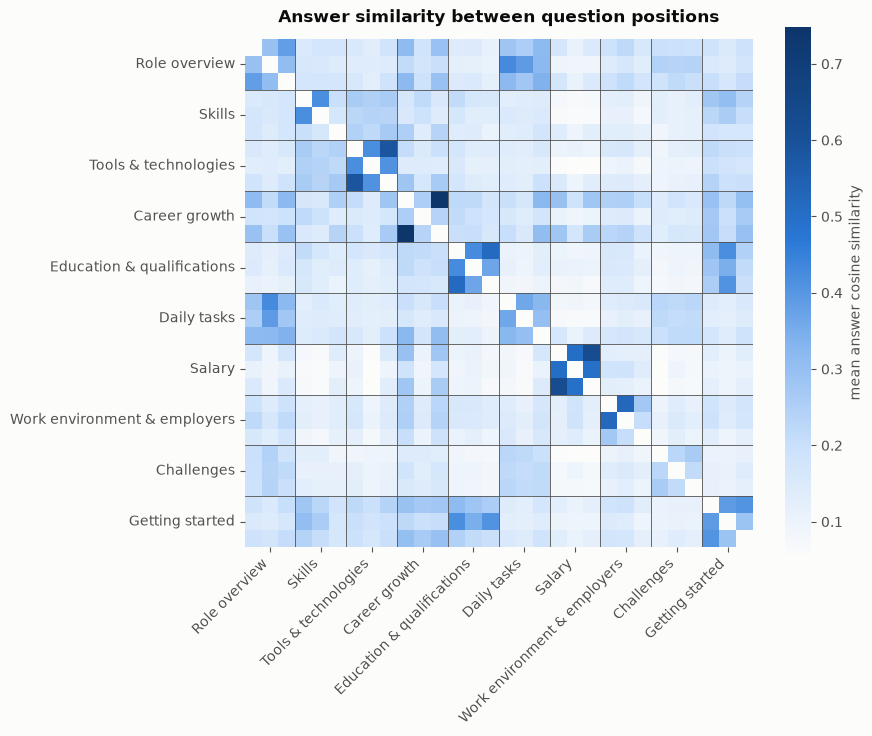

Positions whose most similar position is in the same intent block: 22 / 30


,question template,derived intent,most similar positions (by answers),nearest is in own block
position,,,,
1,What are the main responsibilities of a <ROLE>?,role_overview,"[15, 16, 17]",False
5,Which programming languages are important for a <ROLE>?,skills,"[8, 9, 6]",False
10,How do I progress in a career as a <ROLE>?,career_growth,"[27, 29, 9]",False
15,What does a typical day look like for a <ROLE>?,daily_tasks,"[1, 16, 17]",False
16,What are the daily tasks of a <ROLE>?,daily_tasks,"[1, 15, 17]",False
17,What does a <ROLE> do on a daily basis?,daily_tasks,"[2, 15, 9]",False
25,What difficulties do <ROLE> face in their jobs?,challenges,"[1, 24, 15]",False
28,What are the entry-level requirements for a <ROLE>?,getting_started,"[12, 14, 27]",False


In [8]:
pos = chk.position.to_numpy()
same_role = role_arr[:, None] == role_arr[None, :]
P = np.full((30, 30), np.nan)
for i in range(30):
    for j in range(30):
        if i != j:
            P[i, j] = S[same_role & (pos[:, None] == i) & (pos[None, :] == j)].mean()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(P, cmap=SEQ_BLUES, square=True, cbar_kws={"label": "mean answer cosine similarity"}, ax=ax); ax.grid(False)
for b in range(3, 30, 3):
    ax.axhline(b, color=INK2, lw=0.6); ax.axvline(b, color=INK2, lw=0.6)
ax.set_xticks(np.arange(1.5, 30, 3)); ax.set_xticklabels([INTENT_NAMES[i] for i in INTENTS], rotation=45, ha="right")
ax.set_yticks(np.arange(1.5, 30, 3)); ax.set_yticklabels([INTENT_NAMES[i] for i in INTENTS], rotation=0)
ax.set_title("Answer similarity between question positions", pad=12)
plt.tight_layout(); plt.show()

nearest = pd.DataFrame({"question template": per_pos.most_common_template,
                        "derived intent": [INTENTS[p // 3] for p in range(30)],
                        "most similar positions (by answers)": [np.argsort(-np.nan_to_num(P[i], nan=-1))[:3].tolist() for i in range(30)]})
nearest["nearest is in own block"] = [r[0] // 3 == i // 3 for i, r in enumerate(nearest["most similar positions (by answers)"])]
print(f"Positions whose most similar position is in the same intent block: {nearest['nearest is in own block'].sum()} / 30")
nearest[~nearest["nearest is in own block"]]

Most positions are closest to the other members of their own intent block, so the grouping is confirmed
by the *answers* and not only by the question order. The exceptions are informative — they are questions whose
topic genuinely overlaps another intent (for example *"Which programming languages are important for …?"* has
answers that read like the **tools & technologies** answers, and *"What are the entry-level requirements …?"*
overlaps with **education**). We keep the structural 10 × 3 grouping (it follows the dataset's order and keeps the
classes balanced) but expect these ambiguous positions to cause errors; Section 15 checks this.

**Role names inside questions.** We also check how often the role's name appears in the question text
— this tells us how hard role prediction will be:

In [9]:
base_name = df.role.str.replace(r"\s*\(.*?\)", "", regex=True).str.lower()
contains = [b in q.lower() for b, q in zip(base_name, df.question)]
print(f"Questions that literally contain the role name: {np.mean(contains):.1%}")

Questions that literally contain the role name: 98.0%


## 5. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
q_words,1620.0,9.6,1.6,6.0,9.0,10.0,10.0,16.0
a_words,1620.0,27.8,5.1,15.0,24.0,28.0,31.0,43.0


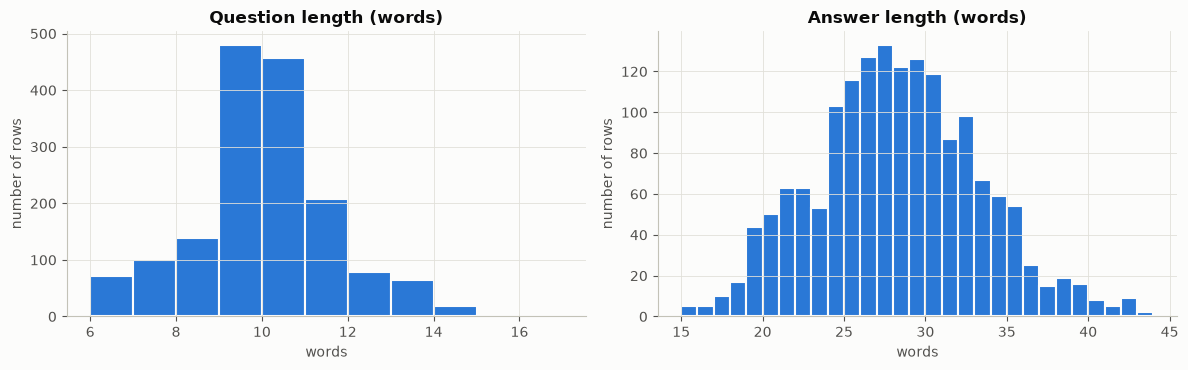

In [10]:
df["q_words"] = df.question.str.split().str.len()
df["a_words"] = df.answer.str.split().str.len()
display(df[["q_words", "a_words"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title in [(axes[0], "q_words", "Question length"), (axes[1], "a_words", "Answer length")]:
    ax.hist(df[col], bins=range(df[col].min(), df[col].max() + 2), color=BLUE, edgecolor="#fcfcfb", linewidth=1.5)
    ax.set(title=f"{title} (words)", xlabel="words", ylabel="number of rows")
plt.tight_layout(); plt.show()

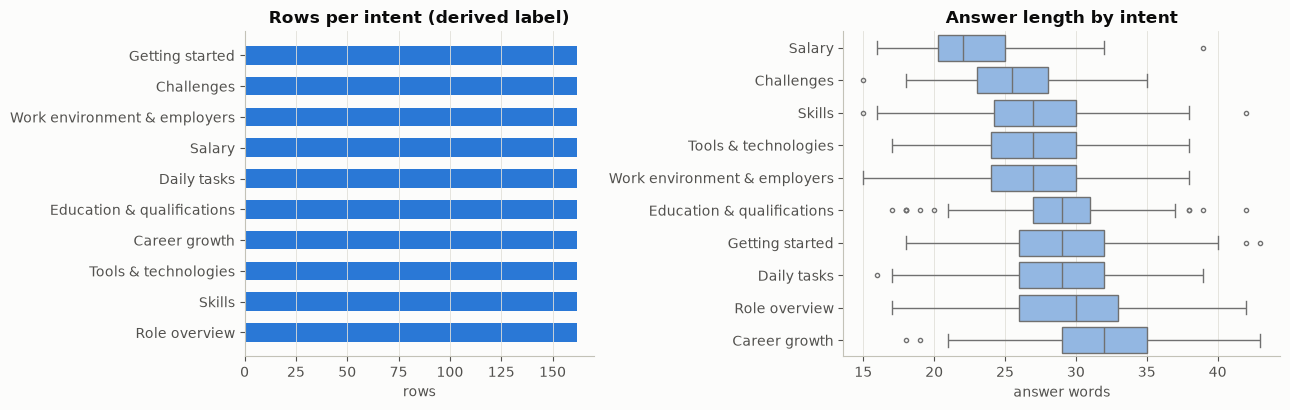

Roles are perfectly balanced: True (30 questions each)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ic = df.intent.map(INTENT_NAMES).value_counts().sort_values()
axes[0].barh(ic.index, ic.values, color=BLUE, height=0.6); axes[0].grid(False, axis="y")
axes[0].set(title="Rows per intent (derived label)", xlabel="rows")
order = df.groupby("intent").a_words.median().sort_values().index
sns.boxplot(data=df, y=df.intent.map(INTENT_NAMES), x="a_words", order=[INTENT_NAMES[i] for i in order],
            ax=axes[1], color="#86b6ef", linewidth=1, fliersize=3)
axes[1].set(title="Answer length by intent", xlabel="answer words", ylabel="")
plt.tight_layout(); plt.show()
print("Roles are perfectly balanced:", role_counts.nunique() == 1, f"({role_counts.iloc[0]} questions each)")

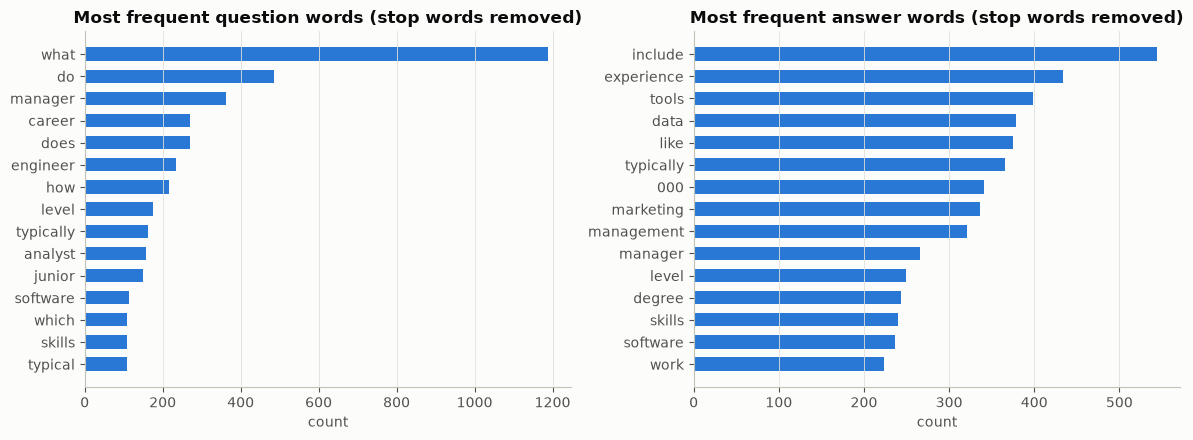

In [12]:
pre_eda = TextPreprocessor(remove_stopwords=True, stem=False)
def top_terms(texts, n=15):
    return pd.Series([t for x in texts for t in pre_eda.tokens(x)]).value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title in [(axes[0], "question", "Most frequent question words"),
                       (axes[1], "answer", "Most frequent answer words")]:
    tt = top_terms(df[col]).sort_values()
    ax.barh(tt.index, tt.values, color=BLUE, height=0.6); ax.grid(False, axis="y")
    ax.set(title=title + " (stop words removed)", xlabel="count")
plt.tight_layout(); plt.show()

In [13]:
# Which words distinguish each intent? Top TF-IDF terms of the questions belonging to each intent.
vec_eda = TfidfVectorizer(preprocessor=pre_eda, token_pattern=r"\S+")
Xq = vec_eda.fit_transform(df.question)
terms = np.array(vec_eda.get_feature_names_out())
rows = {}
for intent in INTENTS:
    mean_w = np.asarray(Xq[(df.intent == intent).to_numpy()].mean(axis=0)).ravel()
    rows[INTENT_NAMES[intent]] = ", ".join(terms[mean_w.argsort()[::-1][:6]])
pd.Series(rows, name="top TF-IDF question terms").to_frame()

,top TF-IDF question terms
Role overview,"responsibilities, description, job, main, what, does"
Skills,"skills, required, successful, essential, important, programming"
Tools & technologies,"proficient, tools, use, software, technologies, role"
Career growth,"career, progress, trajectory, path, growth, typical"
Education & qualifications,"need, educational, qualifications, do, pursue, degree"
Daily tasks,"daily, does, tasks, basis, what, look"
Salary,"salary, range, average, much, earn, annually"
Work environment & employers,"work, environment, expect, where, hire, kind"
Challenges,"challenges, biggest, problems, encounter, difficulties, face"
Getting started,"how, start, entry, working, begin, level"


**EDA findings**
- 1,620 rows, 54 perfectly balanced roles (30 each) and 10 balanced derived intents (162 each).
- Questions are short (≈10 words) and template-based; answers are 15–43 words.
- The role name appears in almost every question, so role prediction should be easy.
- Intent is signalled by a few key words (*salary/earn*, *skills*, *tools/software*, *degree/qualifications* …).
  Each intent has only **3 wordings**, so a model must generalise to wordings it has never seen —
  this is the real NLP challenge in this dataset.

## 6. Text cleaning and NLP preprocessing

`chatbot_core.TextPreprocessor` (shared with the app) applies:
1. **Unicode normalisation** (NFKC) and **lower-casing**;
2. **Tokenisation** with a regular expression (keeps tokens like `c++`, `c#`; strips `'s` from `what's`);
3. **Stop-word removal** using scikit-learn's English list, *except* question words that carry intent
   (`how`, `much`, `where`, `what`, `which`, `why`, `when`, `do`) — e.g. *"where do … work"* signals the
   work-environment intent and *"how much"* signals salary;
4. **Stemming** with NLTK's Snowball stemmer (*earns → earn*, *developers → develop*) **or lemmatisation** with
   NLTK's WordNet lemmatizer (*earns → earn*, *developers → developer* — dictionary forms instead of truncated stems).

The preprocessor runs *inside* the TF-IDF vectorizer, so it is saved with the model and applied
identically at training and inference time. Which combination of steps works best is decided
empirically in Section 11.

**Before** the preprocessor, every *user* query passes through `QueryNormalizer` (shown below): it expands
career abbreviations (*ml → machine learning*, *SRE → site reliability engineer*) and corrects typos towards
words that occur in the knowledge base (*skils → skills*). The sentence encoder has its own sub-word tokenizer,
so the embedding path receives the normalised query text without stop-word removal or stemming.

In [14]:
variants = {"lowercase + tokenise only": TextPreprocessor(False, False),
            "+ stop-word removal": TextPreprocessor(True, False),
            "+ stop-word removal + stemming": TextPreprocessor(True, True),
            "+ stop-word removal + lemmatisation": TextPreprocessor(True, False, lemmatize=True)}
examples = ["How much do Data Scientists earn annually?",
            "What's the career growth path for a Site Reliability Engineer (SRE)?",
            "Which programming languages are important for a Game Developer?"]
pd.DataFrame({name: [p(e) for e in examples] for name, p in variants.items()}, index=examples)

,lowercase + tokenise only,+ stop-word removal,+ stop-word removal + stemming,+ stop-word removal + lemmatisation
How much do Data Scientists earn annually?,how much do data scientists earn annually,how much do data scientists earn annually,how much do data scientist earn annual,how much do data scientist earn annually
What's the career growth path for a Site Reliability Engineer (SRE)?,what the career growth path for a site reliability engineer sre,what career growth path site reliability engineer sre,what career growth path site reliabl engin sre,what career growth path site reliability engineer sre
Which programming languages are important for a Game Developer?,which programming languages are important for a game developer,which programming languages important game developer,which program languag import game develop,which program language important game developer


In [15]:
# Step by step for one question: what each preprocessing stage does.
example = "What's the career growth path for Data Scientists (and developers)?"
stem_p, lem_p = TextPreprocessor(True, True), TextPreprocessor(True, False, lemmatize=True)
import unicodedata
lowered = unicodedata.normalize("NFKC", example).lower()
tokens = TextPreprocessor(False, False).tokens(example)
no_stop = [t for t in tokens if t not in cc.STOP_WORDS]
pd.DataFrame({"stage": ["original", "1. normalise + lower-case", "2. tokenise", "3. remove stop words",
                        "4a. stem (Snowball)", "4b. lemmatise (WordNet)"],
              "output": [example, lowered, tokens, no_stop, stem_p.tokens(example), lem_p.tokens(example)]})

,stage,output
0,original,What's the career growth path for Data Scientists (and developers)?
1,1. normalise + lower-case,what's the career growth path for data scientists (and developers)?
2,2. tokenise,"[what, the, career, growth, path, for, data, scientists, and, developers]"
3,3. remove stop words,"[what, career, growth, path, data, scientists, developers]"
4,4a. stem (Snowball),"[what, career, growth, path, data, scientist, develop]"
5,4b. lemmatise (WordNet),"[what, career, growth, path, data, scientist, developer]"


In [16]:
pd.DataFrame({name: {"vocabulary size (questions)": len({t for q in df.question for t in p.tokens(q)}),
                     "vocabulary size (questions + answers)": len({t for x in pd.concat([df.question, df.answer]) for t in p.tokens(x)})}
              for name, p in variants.items()}).T

,vocabulary size (questions),vocabulary size (questions + answers)
lowercase + tokenise only,187,2391
+ stop-word removal,169,2271
+ stop-word removal + stemming,141,1502
+ stop-word removal + lemmatisation,145,1712


### Query normalisation: abbreviations and typos

Real users write *"ml engineer pay"* or *"what skils does a data scienist need"*. `QueryNormalizer` (fitted on the
knowledge base) rewrites such queries **before** feature extraction:

1. **Aliases** — a short hand-checked list (*ml, swe, sysadmin, bi, dev, admin, ...*) plus acronyms taken
   automatically from the role names, e.g. *(SRE)*, *(CSR)*. Matching uses word boundaries, so *ml* inside
   *html* is not touched.
2. **Typo correction** — words of 4+ letters that are not in the knowledge-base vocabulary are replaced by the
   closest question/role word (`difflib` similarity ≥ 0.84). Unknown words with no close match are kept, so
   off-topic words such as *weather* are never "corrected" into career words.
3. The in-scope check (Section 12) uses the **raw** query, so a correction can never pull an off-topic question
   into the domain.

In [17]:
normalizer = QueryNormalizer.from_kb(df)
demo = ["ml engineer salary", "what is an sre", "what skils does a data scienist need",
        "how much does a sysadmin make", "what's the weather tomorrow"]
pd.DataFrame([{"user query": q, "normalised": (n := normalizer.normalize(q)).text, "changes": n.corrections}
              for q in demo])

,user query,normalised,changes
0,ml engineer salary,machine learning engineer salary,"[(ml, machine learning)]"
1,what is an sre,what is an sre,[]
2,what skils does a data scienist need,what skills does a data scientist need,"[(skils, skills), (scienist, scientist)]"
3,how much does a sysadmin make,how much does a systems administrator make,"[(sysadmin, systems administrator)]"
4,what's the weather tomorrow,what's the weather tomorrow,[]


In [18]:
# The normaliser must not damage the dataset itself: how many stored questions does it change?
changed = [(q, normalizer.normalize(q).corrections) for q in df.question if normalizer.normalize(q).corrections]
print(f"Dataset questions changed by the normaliser: {len(changed)} of {len(df)}")
print("Kinds of change:", sorted({c for _, cs in changed for c in cs}))

Dataset questions changed by the normaliser: 0 of 1620
Kinds of change: []


## 7. Train/test split and data-leakage prevention

A random split would be misleading here: the same question template appears for all 54 roles and the
three paraphrases of a group are near-duplicates in meaning. We therefore use a
**leave-one-paraphrase-out split**:

- **Test set:** paraphrase slot 2 of every (role, intent) group — 540 questions. Every test question uses a
  *wording that never appears in training* (for any role).
- **Training set / knowledge base:** slots 0 and 1 — 1,080 question–answer pairs. Every test question still
  has 2 sibling questions in the knowledge base, so a correct answer exists.
- **Model selection and threshold tuning** use only the training set, with an inner 2-fold split
  (train on slot 0 → validate on slot 1, and vice versa). The test set is used once, in Section 13.
- All vectorizers and classifiers are fitted only on training data (`CareerChatbot.fit` fits everything on the
  knowledge base it is given). The test answers are never used for training.
- The pretrained sentence-embedding model (MiniLM) is *not* trained on our data, so pre-computing its
  embeddings for all rows does not leak test information.

In [19]:
TEST_SLOT = 2
train_df = df[df.paraphrase_slot != TEST_SLOT].reset_index(drop=True)
test_df = df[df.paraphrase_slot == TEST_SLOT].reset_index(drop=True)
inner_folds = [(train_df[train_df.paraphrase_slot != k].reset_index(drop=True),
                train_df[train_df.paraphrase_slot == k].reset_index(drop=True)) for k in (0, 1)]

# Leakage checks
assert not set(train_df.question) & set(test_df.question), "question overlap"
assert not set(train_df.answer) & set(test_df.answer), "answer overlap"
test_templates = set(chk.loc[chk.position % 3 == TEST_SLOT, "template"])
train_templates = set(chk.loc[chk.position % 3 != TEST_SLOT, "template"])
assert (train_df.groupby(["role", "intent"]).size() == 2).all()
print(f"train/KB: {len(train_df)}  test: {len(test_df)}  inner folds: {[ (len(a), len(b)) for a, b in inner_folds ]}")
print(f"Test question templates also present in training: {len(test_templates & train_templates)} of {len(test_templates)}")

train/KB: 1080  test: 540  inner folds: [(540, 540), (540, 540)]
Test question templates also present in training: 0 of 10


**Frozen realistic test sets.** The dataset questions are templated, so we also wrote realistic test data that
looks like what real users type. Both files were written **before any tuning** and are used **only for
evaluation** (never for choosing models, thresholds or aliases). Their SHA-256 hashes are printed so any later
edit would be visible.

- `data/realistic_queries.csv` — 64 questions in 7 categories: informal wording, abbreviations, typos, overlapping
  topics, no career named (*role-free*), careers not in the dataset (*unknown role*), and off-topic questions.
- `data/conversations.csv` — 12 scripted dialogues (30 turns) with follow-up questions such as *"how much do they
  earn?"*, an off-topic interruption, and a switch to another career.

Expected behaviour per row: `answer` (right career **and** topic), `clarify_role` (ask which career), or
`no_answer` (must not give an answer — clarifying or falling back are both acceptable).

In [20]:
realistic, conversations, eval_hashes = ce.load_eval_sets()
for name, h in eval_hashes.items():
    print(f"{name}: sha256 {h}")
display(realistic.category.value_counts().rename("questions").to_frame().T)
print(f"{conversations.dialog_id.nunique()} dialogues, {len(conversations)} turns")
realistic.groupby("category").head(1)[["category", "query", "expected_kind", "expected_role", "expected_intent"]]

realistic_queries.csv: sha256 6aa51fddda344a1156b2787d718d99bb77be01a245302c91fd7ae1c4952a7c5b
conversations.csv: sha256 fde1014b15dd504b9fc070ae1aea5b63efd5e60c890917dda6cd11913093a259


category,informal,off_topic,abbreviation,typo,overlap,role_free,unknown_role
questions,12,12,10,10,6,6,6


12 dialogues, 30 turns


,category,query,expected_kind,expected_role,expected_intent
0,informal,how much money do data scientists make,answer,Data Scientist,salary
12,abbreviation,ml engineer salary,answer,Machine Learning Engineer,salary
22,typo,what skils does a data scienist need,answer,Data Scientist,skills
32,overlap,what programming languages should a game developer know,answer,Game Developer,skills
38,role_free,how much can i earn,clarify_role,,salary
44,unknown_role,how much does a pilot earn,no_answer,,
50,off_topic,how do i write a good resume,no_answer,,


### 7.1 Extra question wordings (training data only)

The dataset has only **3 wordings per topic**, which limits how varied the training questions are. We wrote
**50 additional wordings** (5 per topic, `data/extra_question_templates.csv`), e.g. *"What compensation does a
{role} receive?"*, and fill each one in for all 54 careers. These rows are used **only to train the two
classifiers**; they never become stored answers, and the original dataset is unchanged.

Because the extra wordings were written after the test wordings had been seen, they are checked automatically
before use, so they cannot leak test information:
1. no extra wording may contain a word that occurs **only in the held-out test wording** of its topic
   (e.g. the Skills test wording mentions *programming languages*, so no extra Skills wording may);
2. token overlap (Jaccard, career names masked) with every **test wording** must stay below 0.6;
3. the same overlap limit applies to every **realistic test question and dialogue turn**.
Whether the extra data is actually used is decided on the validation folds in §11.5.

In [21]:
extra_tpl = ce.load_extra_templates()
role_names = list(df.role.unique()) + [cc.role_base_name(r) for r in df.role.unique()]
tpl30 = df.assign(position=df.groupby("role", sort=False).cumcount()).drop_duplicates("position")
tpl30["words"] = [ce.content_words(q, role_names) for q in tpl30.question]
eval_texts = pd.concat([realistic["query"], conversations["query"]]).tolist()
eval_words = [ce.content_words(q, role_names) for q in eval_texts]
checks = []
for t in extra_tpl.itertuples(index=False):
    w = ce.content_words(t.template)
    same = tpl30[tpl30.intent == t.intent]
    test_only = set().union(*same[same.paraphrase_slot == TEST_SLOT].words) - set().union(*same[same.paraphrase_slot != TEST_SLOT].words)
    j_eval, nearest = max((ce.jaccard(w, e), q) for e, q in zip(eval_words, eval_texts))
    checks.append({"intent": t.intent, "wording": t.template, "test-only words used": sorted(w & test_only),
                   "max overlap with test wordings": max(ce.jaccard(w, x) for x in tpl30[tpl30.paraphrase_slot == TEST_SLOT].words),
                   "max overlap with realistic/dialogue tests": j_eval, "nearest realistic/dialogue question": nearest})
checks = pd.DataFrame(checks)
violations = checks[(checks["test-only words used"].str.len() > 0) | (checks["max overlap with test wordings"] >= 0.6)
                    | (checks["max overlap with realistic/dialogue tests"] >= 0.6)]
assert violations.empty, violations
assert not set(extra_tpl.template.str.lower()) & set(t.lower() for t in chk.template.str.replace("<ROLE>", "{role}"))
print(f"{len(extra_tpl)} extra wordings, {extra_tpl.intent.nunique()} topics, leakage violations: {len(violations)}")
EXTRA_ALL = ce.expand_templates(extra_tpl, df.role.unique())
print(f"Expanded to {len(EXTRA_ALL)} extra training questions, e.g.:")
display(EXTRA_ALL.sample(5, random_state=SEED)[["role", "intent", "question"]])
checks.sort_values("max overlap with realistic/dialogue tests", ascending=False).head(5).round(2)

50 extra wordings, 10 topics, leakage violations: 0
Expanded to 2700 extra training questions, e.g.:


,role,intent,question
1339,AI Software Engineer,work_environment,What is the workplace like for a AI Software Engineer?
1222,Cloud Database Engineer,education,What academic background does a Cloud Database Engineer need?
1106,Web Developer,skills,What should I be good at to work as a Web Developer?
812,Salesforce Administrator,tools_technologies,What tech stack is common for a Salesforce Administrator?
1231,Cloud Database Engineer,salary,What compensation does a Cloud Database Engineer receive?


,intent,wording,test-only words used,max overlap with test wordings,max overlap with realistic/dialogue tests,nearest realistic/dialogue question
1,role_overview,Explain the {role} role to me.,[],0.25,0.5,what about a Mobile App Developer?
2,role_overview,What kind of work does a {role} handle?,[],0.29,0.5,what technologies does an automation engineer work with
16,career_growth,Where can a {role} go next in their career?,[],0.50,0.5,what about a Mobile App Developer?
10,tools_technologies,What tools and platforms does a {role} work with?,[],0.29,0.5,what tools does a Data Analyst use?
45,getting_started,How do I get into a {role} career?,[],0.50,0.5,what about a Mobile App Developer?


## 8. Feature extraction using TF-IDF

**TF-IDF** (term frequency × inverse document frequency) represents each question as a sparse vector in
which words that are frequent in the question but rare across the corpus get high weight. We use unigrams
and bigrams (`ngram_range=(1, 2)`), sub-linear TF (`1 + log tf`) and L2-normalised rows, so the dot product
of two vectors is their **cosine similarity**.

In [22]:
vec = cc.build_vectorizer(TextPreprocessor())
X_train = vec.fit_transform(train_df.question)          # fitted on training questions only
terms = vec.get_feature_names_out()
print(f"TF-IDF matrix: {X_train.shape[0]} questions x {X_train.shape[1]} features, "
      f"density {X_train.nnz / np.prod(X_train.shape):.2%}")
idf = pd.Series(vec.idf_, index=terms)
pd.DataFrame({"lowest IDF (common)": idf.nsmallest(8).index, "highest IDF (rare)": idf.nlargest(8).index})

TF-IDF matrix: 1080 questions x 1005 features, density 1.21%


,lowest IDF (common),highest IDF (rare)
0,what,adjust do
1,do,adjust earn
2,manag,adjust face
3,career,adjust role
4,engin,advisor do
5,doe,advisor earn
6,how,advisor face
7,typic,advisor role


In [23]:
q = train_df.question[0]
row = X_train[0].toarray().ravel()
print("Question:", q)
pd.Series(row, index=terms)[row > 0].sort_values(ascending=False).round(3).to_frame("tf-idf weight")

Question: What does a Data Scientist do?


,tf-idf weight
scientist do,0.547
doe data,0.453
scientist,0.370
data scientist,0.370
data,0.290
what doe,0.247
doe,0.217
do,0.144
what,0.096


We also use **sentence embeddings** from pretrained transformer encoders (starting with `all-MiniLM-L6-v2`,
384-dimensional dense vectors). Unlike TF-IDF, embeddings place words with similar meaning
(*salary* ↔ *earn* ↔ *pay*) close together, which should help with unseen wordings. Embeddings are cached by
(encoder, prompt, text) so each text is encoded once per encoder.

**Why these representations?** Section 11.2 compares word unigrams, word 1–2-grams, character n-grams and
sentence embeddings on the validation folds: n-grams capture short phrases (*"how much"*, *"daily basis"*),
character n-grams survive typos, and embeddings capture meaning across different wordings.

In [24]:
EMB = {}
def emb(texts, encoder=cc.EMBEDDING_MODEL, prompt=""):
    texts = list(texts)
    missing = [t for t in dict.fromkeys(texts) if (encoder, prompt, t) not in EMB]
    if missing:
        EMB.update({(encoder, prompt, t): v for t, v in zip(missing, cc.embed(missing, encoder, prompt))})
    return np.vstack([EMB[(encoder, prompt, t)] for t in texts])

t0 = time.time()
all_texts = pd.concat([df.question, df.answer]).tolist()
dim = emb(all_texts).shape[1]
print(f"Embedded {len(all_texts)} texts with {cc.EMBEDDING_MODEL} in {time.time() - t0:.1f}s; dim = {dim}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedded 3240 texts with sentence-transformers/all-MiniLM-L6-v2 in 11.8s; dim = 384


## 9. Model development: approach

The dataset is a knowledge base of question–answer pairs with two (verified) labels per question. A user
question must be mapped to the right stored answer. Two families of methods fit this structure:

| Approach | How it works | Strength | Weakness |
|---|---|---|---|
| **Retrieval** (Section 10) | Vectorise the query, return the answer of the most cosine-similar stored question | Simple, no labels needed | Matches *wording*: "How much do X earn?" may match the same template for a *different* role |
| **Classification** (Section 11) | Predict **role** (54 classes) and **intent** (10 classes) separately with Logistic Regression | Uses the label structure; learns which words signal role vs. topic | Needs labels; one combined decision |

**Chosen design — hybrid (`chatbot_core.CareerChatbot`):**
1. TF-IDF + Logistic Regression predicts the **role** (role names are lexical, so TF-IDF is ideal).
2. Logistic Regression predicts the **intent** from either TF-IDF or sentence-embedding features
   (chosen by validation in Section 11).
3. Within the predicted (role, intent) group, **cosine similarity** selects the closest stored question,
   and its answer is returned.
4. Class probabilities and the best similarity score drive **thresholds** for clarification and fallback (Section 12).

Logistic Regression is used for the deployed classifiers because it is accurate on sparse text features and
gives **class probabilities**, which the confidence thresholds need. Linear SVM and Naive Bayes are compared
as alternatives.

In [25]:
def intent_features(kind, augment, preprocessor=None, encoder=cc.EMBEDDING_MODEL, prompt=""):
    # Returns a function (train_part, eval_part) -> (X_train, y_train, X_eval) for the intent classifier.
    # augment=True also trains on the knowledge-base *answers* (labelled with their question's intent).
    def build(tr, ev):
        texts = pd.concat([tr.question, tr.answer]) if augment else tr.question
        y = pd.concat([tr.intent, tr.intent]) if augment else tr.intent
        if kind == "tfidf":
            v = cc.build_vectorizer(preprocessor or TextPreprocessor()).fit(texts)
            return v.transform(texts), y, v.transform(ev.question)
        return emb(texts, encoder, prompt), y, emb(ev.question, encoder, prompt)
    return build

def inner_cv(build, make_clf, target="intent"):
    # Mean validation accuracy / macro-F1 over the two inner folds (training data only).
    scores = []
    for tr, va in inner_folds:
        X_tr, y_tr, X_va = build(tr, va)
        clf = make_clf().fit(X_tr, y_tr)
        pred = clf.predict(X_va)
        ll = log_loss(va[target], clf.predict_proba(X_va), labels=clf.classes_) if hasattr(clf, "predict_proba") else np.nan
        scores.append([accuracy_score(va[target], pred), f1_score(va[target], pred, average="macro"), ll])
    return dict(zip(["val_accuracy", "val_macro_f1", "val_log_loss"], np.mean(scores, axis=0)))

## 10. Question–answer retrieval using cosine similarity

**Retrieval baseline:** index the knowledge-base questions, and for each query rank all stored questions by
cosine similarity. A retrieved question is **relevant** if it belongs to the same (role, intent) group as the
query (its answer is then a correct response).

**Retrieval metrics**
- **Hit@k** — share of queries with at least one relevant question in the top *k* (Hit@1 = top-1 accuracy).
- **MRR** (mean reciprocal rank) — average of 1 / rank of the first relevant result; rewards ranking the right
  answer high even when it is not first.

In [26]:
def retrieval_metrics(sims, kb, queries, ks=(1, 3, 5)):
    rel = ((kb.role.to_numpy()[None, :] == queries.role.to_numpy()[:, None]) &
           (kb.intent.to_numpy()[None, :] == queries.intent.to_numpy()[:, None]))
    order = np.argsort(-sims, axis=1)
    first = np.take_along_axis(rel, order, axis=1).argmax(axis=1)   # rank (0-based) of first relevant hit
    out = {f"Hit@{k}": (first < k).mean() for k in ks}
    out["MRR"] = (1.0 / (first + 1)).mean()
    return out

def tfidf_sims(kb, queries, preprocessor=None):
    v = cc.build_vectorizer(preprocessor or TextPreprocessor()).fit(kb.question)
    return (v.transform(queries.question) @ v.transform(kb.question).T).toarray()

def emb_sims(kb, queries, encoder=cc.EMBEDDING_MODEL, prompt=""):
    return emb(queries.question, encoder, prompt) @ emb(kb.question, encoder, prompt).T

ret_val = {}
for name, fn in [("TF-IDF cosine retrieval", tfidf_sims), ("MiniLM embedding cosine retrieval", emb_sims)]:
    ret_val[name] = pd.DataFrame([retrieval_metrics(fn(tr, va), tr, va) for tr, va in inner_folds]).mean()
pd.DataFrame(ret_val).T.round(3)

,Hit@1,Hit@3,Hit@5,MRR
TF-IDF cosine retrieval,0.261,0.491,0.598,0.442
MiniLM embedding cosine retrieval,0.763,0.951,0.998,0.860


In [27]:
# What does retrieval return? Top-3 neighbours for one validation query (fold: train on slot 0, validate on slot 1)
tr, va = inner_folds[1]
qi = va.index[(va.role == "Data Analyst") & (va.intent == "salary")][0]
for name, fn in [("TF-IDF", tfidf_sims), ("MiniLM", emb_sims)]:
    s = fn(tr, va.loc[[qi]])[0]
    top = np.argsort(-s)[:3]
    print(f"\n[{name}] query: {va.question[qi]!r}")
    for j in top:
        ok = "✓" if (tr.role[j], tr.intent[j]) == (va.role[qi], va.intent[qi]) else "✗"
        print(f"   {ok} {s[j]:.3f}  {tr.question[j]}  ({tr.role[j]} / {tr.intent[j]})")


[TF-IDF] query: 'How much do Data Analysts earn annually?'
   ✗ 0.702  Where do Data Analysts typically work?  (Data Analyst / work_environment)
   ✗ 0.525  How do I start a career as a Data Analyst?  (Data Analyst / getting_started)
   ✗ 0.479  What does a Data Analyst do?  (Data Analyst / role_overview)

[MiniLM] query: 'How much do Data Analysts earn annually?'
   ✓ 0.865  What is the average salary for a Data Analyst?  (Data Analyst / salary)
   ✗ 0.769  What is the average salary for a Data Scientist?  (Data Scientist / salary)
   ✗ 0.765  Where do Data Analysts typically work?  (Data Analyst / work_environment)


Pure retrieval often matches the **template** rather than the meaning: a salary question can retrieve the
identical wording for another role. This motivates predicting role and intent separately (Section 11).

## 11. Classification models

### 11.1 Role classifier (54 classes)

In [28]:
role_build = lambda tr, va: (lambda v: (v.transform(tr.question), tr.role, v.transform(va.question)))(
    cc.build_vectorizer(TextPreprocessor()).fit(tr.question))
role_results = {
    "TF-IDF + Logistic Regression": inner_cv(role_build, lambda: LogisticRegression(C=10, max_iter=5000), "role"),
    "TF-IDF + Linear SVM": inner_cv(role_build, lambda: LinearSVC(C=1), "role"),
    "TF-IDF + Complement NB": inner_cv(role_build, lambda: ComplementNB(alpha=0.3), "role"),
}
pd.DataFrame(role_results).T.round(3)

,val_accuracy,val_macro_f1,val_log_loss
TF-IDF + Logistic Regression,1.0,1.0,0.041
TF-IDF + Linear SVM,1.0,1.0,NaN
TF-IDF + Complement NB,1.0,1.0,1.176


As expected from Section 4, role prediction is easy because the role name is in the question; all
models are close to perfect. Logistic Regression is kept for its probabilities.

### 11.2 Representation comparison (rubric 3)

Which text representation suits which sub-task? Each representation feeds the same Logistic Regression
(C = 10), trained on one paraphrase slot and validated on the other (inner folds). For the **role** task we
also corrupt the validation questions with random typos (one letter dropped in ~40% of words of 5+ letters)
to see which representation survives misspellings.

In [29]:
rng = np.random.default_rng(SEED)
def add_typos(text, p=0.4):
    out = []
    for w in text.split():
        if len(w) >= 5 and rng.random() < p:
            i = int(rng.integers(1, len(w) - 1)); w = w[:i] + w[i + 1:]
        out.append(w)
    return " ".join(out)

representations = {
    "TF-IDF word unigrams": lambda: cc.build_vectorizer(TextPreprocessor(True, False), (1, 1)),
    "TF-IDF word 1-2-grams": lambda: cc.build_vectorizer(TextPreprocessor(True, False), (1, 2)),
    "TF-IDF character 2-5-grams": lambda: cc.build_vectorizer(TextPreprocessor(False, False), (2, 5), "char_wb"),
    "MiniLM sentence embeddings": None,
}
noisy_folds = [va.question.map(add_typos) for _, va in inner_folds]   # the same typos for every representation
rows = []
for name, make_vec in representations.items():
    res = {"representation": name}
    for target in ["role", "intent"]:
        accs, f1s, noisy = [], [], []
        for (tr, va), va_noisy in zip(inner_folds, noisy_folds):
            if make_vec is None:
                X_tr, X_va, X_no = emb(tr.question), emb(va.question), cc.embed(list(va_noisy))
            else:
                v = make_vec().fit(tr.question)
                X_tr, X_va, X_no = v.transform(tr.question), v.transform(va.question), v.transform(va_noisy)
            clf = LogisticRegression(C=10, max_iter=5000).fit(X_tr, tr[target])
            pred = clf.predict(X_va)
            accs.append(accuracy_score(va[target], pred)); f1s.append(f1_score(va[target], pred, average="macro"))
            noisy.append(accuracy_score(va[target], clf.predict(X_no)))
        res[f"{target} val accuracy"] = np.mean(accs)
        res[f"{target} val macro-F1"] = np.mean(f1s)
        res[f"{target} accuracy with typos"] = np.mean(noisy)
    rows.append(res)
rep_cmp = pd.DataFrame(rows).set_index("representation")
rep_cmp.round(3)

,role val accuracy,role val macro-F1,role accuracy with typos,intent val accuracy,intent val macro-F1,intent accuracy with typos
representation,,,,,,
TF-IDF word unigrams,1.0,1.0,0.778,0.359,0.283,0.295
TF-IDF word 1-2-grams,1.0,1.0,0.777,0.350,0.270,0.294
TF-IDF character 2-5-grams,1.0,1.0,0.998,0.246,0.159,0.233
MiniLM sentence embeddings,1.0,1.0,0.857,0.781,0.749,0.649


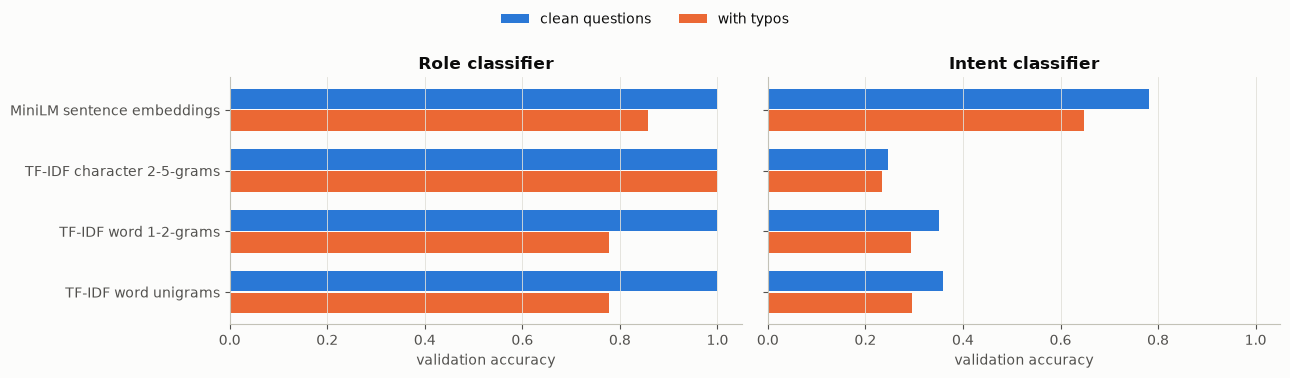

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, target in zip(axes, ["role", "intent"]):
    y = np.arange(len(rep_cmp))
    ax.barh(y + 0.18, rep_cmp[f"{target} val accuracy"], height=0.34, color=BLUE, label="clean questions")
    ax.barh(y - 0.18, rep_cmp[f"{target} accuracy with typos"], height=0.34, color=ORANGE, label="with typos")
    ax.set_yticks(y); ax.set_yticklabels(rep_cmp.index); ax.grid(False, axis="y")
    ax.set(xlim=(0, 1.05), xlabel="validation accuracy", title=f"{target.capitalize()} classifier")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

**Reading the comparison (why each representation is used where it is):**
- **Role:** the career name is written in the question, so lexical features are enough. Word n-grams are near
  perfect on clean text; character n-grams and the query normaliser are what keep the role correct when the
  name is misspelled. The deployed role classifier uses TF-IDF word 1–2-grams on *normalised* queries.
- **Intent:** the test wordings differ from the training wordings, so the model has to recognise *meaning*.
  Sentence embeddings are far ahead of every TF-IDF variant here, which is why the intent classifier uses
  embeddings (the encoder is chosen in §11.4).
- **Bigrams vs unigrams:** bigrams add phrase information (*"how much"*, *"daily basis"*) at almost no cost.

### 11.3 Intent classifier (10 classes) — feature and model comparison

The intent must be recognised from a **wording not seen in training**. We compare feature sets
(TF-IDF vs. MiniLM embeddings, with or without the knowledge-base answers as extra training text) and
classifiers, using inner validation only.

In [31]:
t0 = time.time()
candidates = []
for feat in ["tfidf", "embedding"]:
    for augment in [False, True]:
        build = intent_features(feat, augment)
        clfs = {"Logistic Regression": lambda: LogisticRegression(C=10, max_iter=5000),
                "Linear SVM": lambda: LinearSVC(C=1)}
        if feat == "tfidf":
            clfs["Complement NB"] = lambda: ComplementNB(alpha=0.3)
        for clf_name, make in clfs.items():
            candidates.append({"features": feat, "train on answers too": augment, "classifier": clf_name,
                               **inner_cv(build, make)})
intent_cmp = pd.DataFrame(candidates).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
print(f"({time.time() - t0:.1f}s)")
intent_cmp.round(3)

(4.4s)


,features,train on answers too,classifier,val_accuracy,val_macro_f1,val_log_loss
0,embedding,False,Linear SVM,0.799,0.766,NaN
1,embedding,True,Linear SVM,0.794,0.760,NaN
2,embedding,False,Logistic Regression,0.781,0.749,0.928
3,embedding,True,Logistic Regression,0.776,0.740,0.812
4,tfidf,True,Linear SVM,0.583,0.493,NaN
5,tfidf,True,Logistic Regression,0.542,0.452,1.697
6,tfidf,True,Complement NB,0.502,0.399,1.850
7,tfidf,False,Linear SVM,0.400,0.312,NaN
8,tfidf,False,Logistic Regression,0.396,0.308,2.090
9,tfidf,False,Complement NB,0.377,0.306,2.047


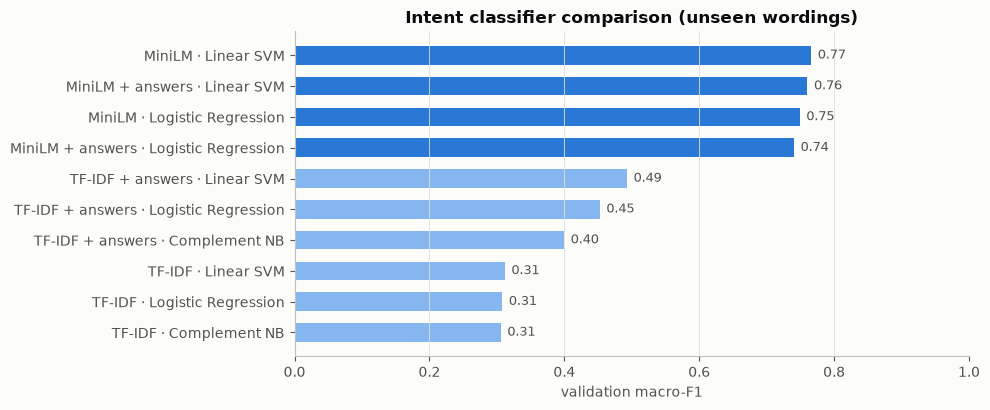

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.2))
lbl = intent_cmp.apply(lambda r: f"{'MiniLM' if r.features == 'embedding' else 'TF-IDF'}"
                                 f"{' + answers' if r['train on answers too'] else ''} · {r.classifier}", axis=1)
plot = intent_cmp.assign(label=lbl).sort_values("val_macro_f1")
colors = [BLUE if f == "embedding" else "#86b6ef" for f in plot.features]
ax.barh(plot.label, plot.val_macro_f1, color=colors, height=0.6); ax.grid(False, axis="y")
for y, v in enumerate(plot.val_macro_f1):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK2, fontsize=9)
ax.set(xlim=(0, 1), xlabel="validation macro-F1", title="Intent classifier comparison (unseen wordings)")
plt.tight_layout(); plt.show()

### 11.4 Choosing the sentence encoder

The comparison above used MiniLM. Several small pretrained encoders run on an ordinary laptop CPU; we compare them
for the intent task on the **validation folds only** (the test slot is not used), with the best Logistic
Regression feature setting from §11.3. `e5-small-v2` expects the prefix `"query: "` on every text.

In [33]:
best_lr = intent_cmp[intent_cmp.classifier == "Logistic Regression"].iloc[0]
BEST_AUGMENT = bool(best_lr["train on answers too"])
ENCODERS = {"all-MiniLM-L6-v2": (cc.EMBEDDING_MODEL, ""),
            "e5-small-v2": ("intfloat/e5-small-v2", "query: "),
            "bge-small-en-v1.5": ("BAAI/bge-small-en-v1.5", ""),
            "snowflake-arctic-embed-xs": ("Snowflake/snowflake-arctic-embed-xs", "")}
enc_rows = []
if best_lr.features == "embedding":
    for label, (name, prompt) in ENCODERS.items():
        t0 = time.time(); emb(pd.concat([df.question, df.answer]), name, prompt); enc_s = time.time() - t0
        res = inner_cv(intent_features("embedding", BEST_AUGMENT, encoder=name, prompt=prompt),
                       lambda: LogisticRegression(C=10, max_iter=5000))
        t0 = time.perf_counter()
        for _ in range(20):
            cc.embed(["how much does a data analyst earn"], name, prompt)
        enc_rows.append({"encoder": label, **res, "dim": emb(["x"], name, prompt).shape[1],
                         "ms per query (CPU)": (time.perf_counter() - t0) / 20 * 1000})
    enc_cmp = pd.DataFrame(enc_rows).set_index("encoder").sort_values("val_macro_f1", ascending=False)
    display(enc_cmp.round(3))
    BEST_ENC_LABEL = enc_cmp.index[0]
else:
    BEST_ENC_LABEL = "all-MiniLM-L6-v2"
BEST_ENC, BEST_PROMPT = ENCODERS[BEST_ENC_LABEL]
print("Selected encoder:", BEST_ENC_LABEL)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

,val_accuracy,val_macro_f1,val_log_loss,dim,ms per query (CPU)
encoder,,,,,
e5-small-v2,0.809,0.783,1.180,384,17.224
bge-small-en-v1.5,0.798,0.776,0.766,384,18.852
all-MiniLM-L6-v2,0.781,0.749,0.928,384,8.883
snowflake-arctic-embed-xs,0.744,0.721,1.209,384,9.974


Selected encoder: e5-small-v2


**Preprocessing ablation** (TF-IDF + answers + Logistic Regression) and **regularisation strength** for the selected feature set:

In [34]:
ablation = pd.DataFrame({name: inner_cv(intent_features("tfidf", True, p), lambda: LogisticRegression(C=10, max_iter=5000))
                         for name, p in variants.items()}).T
display(ablation.round(3))
BEST_PRE_NAME = ablation.val_macro_f1.idxmax()
BEST_PRE = variants[BEST_PRE_NAME]

c_grid = pd.DataFrame({C: inner_cv(intent_features(best_lr.features, BEST_AUGMENT, BEST_PRE, BEST_ENC, BEST_PROMPT),
                                   lambda C=C: LogisticRegression(C=C, max_iter=5000))
                       for C in [0.1, 1, 10, 100]}).T.rename_axis("C")
display(c_grid.round(3))

BEST_CONFIG = dict(intent_features=best_lr.features, augment_with_answers=BEST_AUGMENT,
                   intent_C=float(c_grid.val_log_loss.idxmin()), role_C=10.0, preprocessor=BEST_PRE,
                   encoder=BEST_ENC, encoder_prompt=BEST_PROMPT)
print("Selected configuration:", {k: v for k, v in BEST_CONFIG.items()})

,val_accuracy,val_macro_f1,val_log_loss
lowercase + tokenise only,0.337,0.265,2.109
+ stop-word removal,0.565,0.472,1.725
+ stop-word removal + stemming,0.542,0.452,1.697
+ stop-word removal + lemmatisation,0.541,0.442,1.708


,val_accuracy,val_macro_f1,val_log_loss
C,,,
0.1,0.809,0.775,2.146
1.0,0.813,0.786,1.575
10.0,0.809,0.783,1.180
100.0,0.796,0.769,1.060


Selected configuration: {'intent_features': 'embedding', 'augment_with_answers': False, 'intent_C': 100.0, 'role_C': 10.0, 'preprocessor': TextPreprocessor(remove_stopwords=True, stem=False, lemmatize=False), 'encoder': 'intfloat/e5-small-v2', 'encoder_prompt': 'query: '}


The selection is made programmatically from validation scores (no test data involved):
- **feature set:** the Logistic Regression candidate with the best validation macro-F1;
- **encoder:** the sentence encoder with the best validation macro-F1 (§11.4);
- **preprocessing:** the variant with the best macro-F1 (only affects TF-IDF features — the role classifier and TF-IDF retrieval);
- **regularisation `C`:** the lowest validation **log-loss**. Macro-F1 barely changes with `C`, but strong regularisation
  produces flat, under-confident probabilities. Because the probabilities drive the thresholds (Section 12) and the
  confidence shown in the app, probability quality (log-loss, a proper scoring rule) is the right criterion here.

Logistic Regression is used for the deployed model even if Linear SVM scores slightly higher, because the
thresholds need class probabilities.

### 11.5 Does the extra training data help?

The extra wordings (§7.1) are compared **with vs without**, on the validation folds only, using the selected
encoder, preprocessing and `C`. They are kept only if the validation macro-F1 of the topic classifier improves
and the joint (career + topic) accuracy does not drop; otherwise they are not used.

In [35]:
extra_rows = []
for k, (tr, va) in enumerate(inner_folds):
    for use in (False, True):
        q_tr = pd.concat([tr.question, EXTRA_ALL.question]) if use else tr.question
        y_int = pd.concat([tr.intent, EXTRA_ALL.intent]) if use else tr.intent
        y_role = pd.concat([tr.role, EXTRA_ALL.role]) if use else tr.role
        int_clf = LogisticRegression(C=BEST_CONFIG["intent_C"], max_iter=5000).fit(emb(q_tr, BEST_ENC, BEST_PROMPT), y_int)
        X_va = emb(va.question, BEST_ENC, BEST_PROMPT)
        v = cc.build_vectorizer(BEST_PRE).fit(q_tr)
        role_clf = LogisticRegression(C=10, max_iter=5000).fit(v.transform(q_tr), y_role)
        p_int, p_role = int_clf.predict(X_va), role_clf.predict(v.transform(va.question))
        extra_rows.append({"fold": k, "extra wordings": use, "intent val accuracy": accuracy_score(va.intent, p_int),
                           "intent val macro-F1": f1_score(va.intent, p_int, average="macro"),
                           "intent val log-loss": log_loss(va.intent, int_clf.predict_proba(X_va), labels=int_clf.classes_),
                           "role val accuracy": accuracy_score(va.role, p_role),
                           "joint val accuracy": ((p_int == va.intent.to_numpy()) & (p_role == va.role.to_numpy())).mean()})
extra_cmp = pd.DataFrame(extra_rows).groupby("extra wordings").mean().drop(columns="fold")
display(extra_cmp.round(3))
gain = extra_cmp.loc[True, "intent val macro-F1"] - extra_cmp.loc[False, "intent val macro-F1"]
USE_EXTRA = bool(gain > 0.005 and extra_cmp.loc[True, "joint val accuracy"] >= extra_cmp.loc[False, "joint val accuracy"])
EXTRA = EXTRA_ALL if USE_EXTRA else None
print(f"Validation macro-F1 change with the extra wordings: {gain:+.3f} -> extra training data "
      f"{'USED' if USE_EXTRA else 'NOT used'}")

,intent val accuracy,intent val macro-F1,intent val log-loss,role val accuracy,joint val accuracy
extra wordings,,,,,
False,0.796,0.769,1.060,1.0,0.796
True,0.897,0.880,0.352,1.0,0.897


Validation macro-F1 change with the extra wordings: +0.111 -> extra training data USED


## 12. Response selection, confidence thresholds and fallback responses

For each query the chatbot computes three signals and applies one policy
(`CareerChatbot.decide`, used by both this notebook and the app):

| Signal | Meaning |
|---|---|
| `max_similarity` | cosine similarity of the query to the closest stored question (any group) |
| `role_conf` | probability of the predicted role |
| `intent_conf` | probability of the predicted intent |

| Condition | Response |
|---|---|
| `max_similarity < min_similarity`, or both confidences low | **fallback** — out of scope, explain what the bot can do |
| role confidence low, intent confident | **clarify_role** — "which career do you mean?" |
| intent confidence low, role confident | **clarify_intent** — list the topics the bot knows |
| otherwise | **answer** — the closest stored question within the predicted (role, intent) group |
| answer, but top-2 intents nearly tied | answer **plus** a non-blocking *"Did you mean …?"* offer for the second topic |
| several careers listed in one question | the role classifier runs on each listed part; the topic is answered for every confident career |
| greeting, thanks, help, "best job for me?", "jobs for computer science" | recognised by embedding similarity to example phrases (§12.1); career suggestions rank the 54 careers by similarity to the user's interests |

In a conversation, a missing career or topic is filled from the previous turn (follow-up memory, §13.3).

**Calibration data (training side only).** The thresholds are learned from
(a) out-of-fold predictions on the training questions (inner folds) — in-domain questions;
(b) the same validation questions with synthetic typos (from §11.2), because real users misspell words and a
misspelled career question must still count as in scope;
(c) small hand-written sets of **out-of-domain** questions and **role-free** career questions, written for this
project and labelled as such. Separate hand-written sets are kept aside for testing in Section 13.

The in-scope check can compare either the raw query or the normalised (typo-corrected) query with the stored
questions; both are calibrated below and the one with the better balanced accuracy is used (ties go to the raw
query, the safer choice).

In [36]:
# Hand-written query sets (NOT from the dataset). Calibration and test sets are disjoint.
OOD_CALIB = ["what's the weather like today", "tell me a joke", "who won the football match yesterday",
             "how do i cook pasta", "what is the capital of france", "recommend a good movie",
             "how tall is mount everest", "play some music", "what time is it", "translate hello into spanish",
             "my laptop won't turn on", "best pizza place near me", "how do plants grow", "what is 2 plus 2",
             "write a poem about the sea"]
OOD_TEST = ["how do i fix a flat tire", "who is the president of the united states", "what's a good recipe for cookies",
            "how far is the moon", "can you book me a flight", "what is the meaning of life", "how to lose weight fast",
            "which phone should i buy", "tell me about the history of rome", "how do i train my dog",
            "is it going to rain tomorrow", "what is quantum physics", "how many legs does a spider have",
            "sing me a song", "what's the score of the game"]
ROLEFREE_CALIB = ["what is the average salary?", "how do i start my career?", "what skills do i need?",
                  "what tools should i learn?", "what does a typical workday look like?", "do i need a degree?"]
ROLEFREE_TEST = ["how much can i earn?", "what are the biggest challenges in this job?", "what qualifications are required?",
                 "how can i grow in my career?", "where would i work?", "what are the main responsibilities?"]

GATE_MODES = {"raw query": True, "normalised query": False}
cal = {m: {"in": [], "typo": [], "ood": [], "rf": []} for m in GATE_MODES}
for (tr, va), va_noisy in zip(inner_folds, noisy_folds):
    bot = CareerChatbot(**BEST_CONFIG).fit(tr, extra=EXTRA)
    for mode, raw_gate in GATE_MODES.items():
        bot.gate_on_raw = raw_gate
        p = bot.predict(va.question)
        role_ok = p.pred_role.to_numpy() == va.role.to_numpy()
        p["correct"] = role_ok & (p.pred_intent.to_numpy() == va.intent.to_numpy())
        p["top2_ok"] = role_ok & (p.intent2.to_numpy() == va.intent.to_numpy())
        cal[mode]["in"].append(p); cal[mode]["typo"].append(bot.predict(list(va_noisy)))
        cal[mode]["ood"].append(bot.predict(OOD_CALIB)); cal[mode]["rf"].append(bot.predict(ROLEFREE_CALIB))
cal = {m: {k: pd.concat(v, ignore_index=True) for k, v in d.items()} for m, d in cal.items()}
GRID_T = np.linspace(0, 1, 1001)

def separating_threshold(pos, neg):
    # Threshold maximising balanced accuracy (pos kept, neg rejected); ties -> middle of the best range.
    bal = np.array([((pos >= t).mean() + (neg < t).mean()) / 2 for t in GRID_T])
    best = GRID_T[bal >= bal.max() - 1e-12]
    return float(np.median(best)), float(bal.max())

# In-scope check: career questions (clean, with typos, role-free) must pass, off-topic questions must not.
gate_rows = {}
for mode, d in cal.items():
    pos = np.r_[d["in"].max_similarity, d["typo"].max_similarity, d["rf"].max_similarity]
    t, bal = separating_threshold(pos, d["ood"].max_similarity.to_numpy())
    gate_rows[mode] = {"threshold": t, "balanced accuracy": bal,
                       "career questions with typos kept": (d["typo"].max_similarity >= t).mean(),
                       "off-topic rejected": (d["ood"].max_similarity < t).mean()}
gate_cmp = pd.DataFrame(gate_rows).T
display(gate_cmp.round(3))
GATE_MODE = max(gate_rows, key=lambda m: (round(gate_rows[m]["balanced accuracy"], 6), m == "raw query"))
BEST_CONFIG["gate_on_raw"] = GATE_MODES[GATE_MODE]
cal_in, cal_typo, cal_ood, cal_rf = (cal[GATE_MODE][k] for k in ("in", "typo", "ood", "rf"))
print("In-scope check uses the", GATE_MODE)
pd.DataFrame({name: d[["max_similarity", "role_conf", "intent_conf"]].median()
              for name, d in [("in-domain (OOF)", cal_in), ("in-domain with typos", cal_typo), ("role-free", cal_rf),
                              ("out-of-domain", cal_ood)]}).T.round(3)

,threshold,balanced accuracy,career questions with typos kept,off-topic rejected
raw query,0.836,0.964,0.922,0.967
normalised query,0.864,1.000,1.000,1.000


In-scope check uses the normalised query


,max_similarity,role_conf,intent_conf
in-domain (OOF),0.956,0.993,0.974
in-domain with typos,0.947,0.994,0.931
role-free,0.890,0.027,0.992
out-of-domain,0.784,0.024,0.510


In [37]:
def utility_threshold(conf, correct):
    # Answer only when it pays off: +1 per correct answer, -1 per wrong answer, 0 when asking to clarify.
    util = np.array([(correct & (conf >= t)).sum() - (~correct & (conf >= t)).sum() for t in GRID_T])
    best = GRID_T[util == util.max()]
    return float(np.median(best)), int(util.max())

t_sim, bal_sim = gate_rows[GATE_MODE]["threshold"], gate_rows[GATE_MODE]["balanced accuracy"]
t_role, bal_role = separating_threshold(cal_in.role_conf.to_numpy(), np.r_[cal_rf.role_conf, cal_ood.role_conf])
t_int, util_int = utility_threshold(cal_in.intent_conf.to_numpy(), cal_in.correct.to_numpy())
# "Did you mean": offer the second topic when the top-2 intent probabilities are close. Choose the largest
# margin that flags at most 20% of answered questions (validation folds), so the offer stays occasional.
margin = (cal_in.intent_conf - cal_in.intent2_conf).to_numpy()
answered = cal_in.intent_conf.to_numpy() >= t_int
M_GRID = np.linspace(0, 0.6, 61)
flag_rate = np.array([(margin[answered] < m).mean() for m in M_GRID])
t_amb = float(M_GRID[flag_rate <= 0.20].max())
flag = answered & (margin < t_amb)
caught = (flag & ~cal_in.correct.to_numpy() & cal_in.top2_ok.to_numpy()).sum()
THRESHOLDS = Thresholds(min_similarity=round(t_sim, 3), min_role_conf=round(t_role, 3), min_intent_conf=round(t_int, 3),
                        max_ambiguity_margin=round(t_amb, 3))
print(f"max_ambiguity_margin = {THRESHOLDS.max_ambiguity_margin}  (flags {flag[answered].mean():.1%} of answered validation "
      f"questions; {caught} of {(~cal_in.correct.to_numpy() & answered).sum()} wrong answers get the right topic offered)")
print(f"min_similarity  = {THRESHOLDS.min_similarity}  (balanced accuracy in-scope vs out-of-domain: {bal_sim:.3f})")
print(f"min_role_conf   = {THRESHOLDS.min_role_conf}  (balanced accuracy role-named vs role-free/OOD: {bal_role:.3f})")
print(f"min_intent_conf = {THRESHOLDS.min_intent_conf}  (max utility on {len(cal_in)} OOF questions: {util_int})")

max_ambiguity_margin = 0.6  (flags 3.5% of answered validation questions; 4 of 69 wrong answers get the right topic offered)
min_similarity  = 0.864  (balanced accuracy in-scope vs out-of-domain: 1.000)
min_role_conf   = 0.312  (balanced accuracy role-named vs role-free/OOD: 1.000)
min_intent_conf = 0.603  (max utility on 1080 OOF questions: 875)


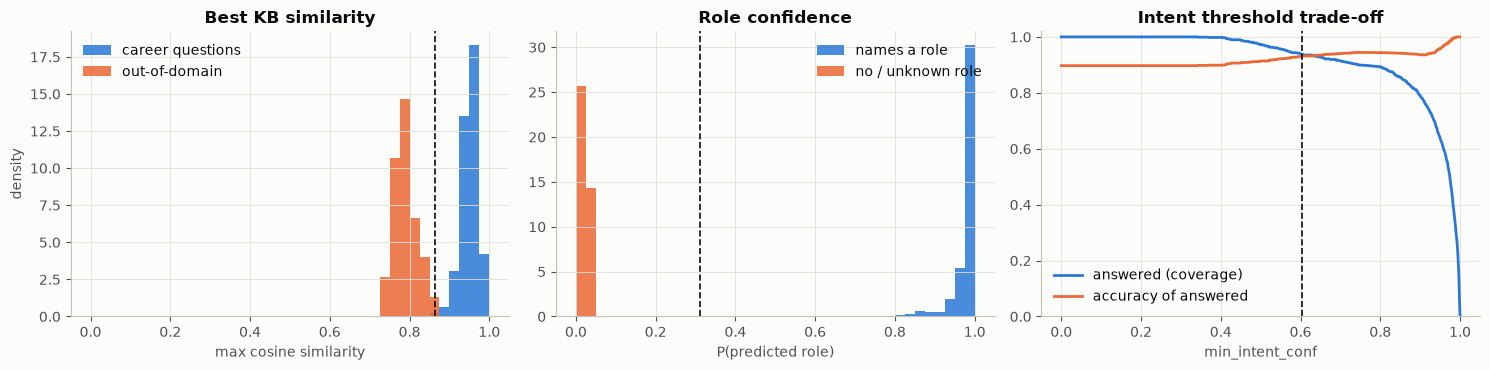

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axes[0]
bins = np.linspace(0, 1, 41)
ax.hist(np.r_[cal_in.max_similarity, cal_typo.max_similarity, cal_rf.max_similarity], bins=bins, color=BLUE, alpha=0.85, density=True, label="career questions")
ax.hist(cal_ood.max_similarity, bins=bins, color=ORANGE, alpha=0.85, density=True, label="out-of-domain")
ax.axvline(THRESHOLDS.min_similarity, color=INK, ls="--", lw=1.2)
ax.set(title="Best KB similarity", xlabel="max cosine similarity", ylabel="density"); ax.legend(frameon=False)

ax = axes[1]
ax.hist(cal_in.role_conf, bins=bins, color=BLUE, alpha=0.85, density=True, label="names a role")
ax.hist(np.r_[cal_rf.role_conf, cal_ood.role_conf], bins=bins, color=ORANGE, alpha=0.85, density=True, label="no / unknown role")
ax.axvline(THRESHOLDS.min_role_conf, color=INK, ls="--", lw=1.2)
ax.set(title="Role confidence", xlabel="P(predicted role)"); ax.legend(frameon=False)

ax = axes[2]
conf, corr = cal_in.intent_conf.to_numpy(), cal_in.correct.to_numpy()
coverage = [(conf >= t).mean() for t in GRID_T]
sel_acc = [corr[conf >= t].mean() if (conf >= t).any() else np.nan for t in GRID_T]
ax.plot(GRID_T, coverage, color=BLUE, lw=2, label="answered (coverage)")
ax.plot(GRID_T, sel_acc, color=ORANGE, lw=2, label="accuracy of answered")
ax.axvline(THRESHOLDS.min_intent_conf, color=INK, ls="--", lw=1.2)
ax.set(title="Intent threshold trade-off", xlabel="min_intent_conf", ylim=(0, 1.02)); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

### 12.1 Small talk and career discovery

Users also greet the bot, say thanks, ask what it can do, ask *"what is the best job for me?"* or *"list the jobs
for computer science"* — none of which the QA dataset answers. These **conversation-level intents** are recognised
by **semantic similarity**: `data/meta_intents.csv` holds 56 short example phrases (greeting, thanks, help,
recommend, list_careers); a message is matched to its most similar example (sentence embeddings), but only when
that similarity beats a calibrated threshold **and** the best similarity to any stored career question. A message
the normal pipeline would answer with a clarification ("which career?") is only taken over when the example wins by
a calibrated **margin**, so role-free career questions such as *"what skills do I need?"* keep their clarification.

- **Recommend / list careers:** every career gets a *profile vector* = the mean embedding of its stored answers.
  The interest or field words of the message (e.g. *coding, maths* or *computer science*) are embedded and the
  careers are ranked by cosine similarity — a semantic search over the knowledge base. Without interest words the
  bot first asks what the user enjoys.
- **Calibration:** leave-one-out over the example phrases gives the in-class similarities (positives) and the
  hand-written off-topic calibration set gives negatives; the separating threshold is chosen as in §12. The margin
  is calibrated the same way with the role-free calibration questions as negatives.

In [39]:
META = pd.read_csv("data/meta_intents.csv")
E_meta = emb(META.example, BEST_ENC, BEST_PROMPT)
S_meta = E_meta @ E_meta.T
np.fill_diagonal(S_meta, -1)
loo_pred = META.intent.to_numpy()[S_meta.argmax(1)]
neg_meta = (emb(OOD_CALIB, BEST_ENC, BEST_PROMPT) @ E_meta.T).max(1)
t_meta, bal_meta = separating_threshold(S_meta.max(1), neg_meta)
THRESHOLDS.min_meta_similarity = round(t_meta, 3)
kb_sim = lambda texts: (emb(texts, BEST_ENC, BEST_PROMPT) @ emb(df.question, BEST_ENC, BEST_PROMPT).T).max(1)
pos_margin = S_meta.max(1) - kb_sim(META.example)
neg_margin = (emb(ROLEFREE_CALIB, BEST_ENC, BEST_PROMPT) @ E_meta.T).max(1) - kb_sim(ROLEFREE_CALIB)
t_margin, bal_margin = separating_threshold(pos_margin, neg_margin)
THRESHOLDS.min_meta_margin = round(t_margin, 3)
print(f"min_meta_margin = {THRESHOLDS.min_meta_margin} (balanced accuracy examples vs role-free career questions: {bal_margin:.3f})")
print(f"{len(META)} example phrases, {META.intent.nunique()} intents; leave-one-out nearest-example accuracy: "
      f"{(loo_pred == META.intent.to_numpy()).mean():.3f}")
print(f"min_meta_similarity = {THRESHOLDS.min_meta_similarity} (balanced accuracy examples vs off-topic: {bal_meta:.3f})")
pd.crosstab(pd.Series(META.intent, name="true"), pd.Series(loo_pred, name="nearest example"))

min_meta_margin = 0.02 (balanced accuracy examples vs role-free career questions: 0.977)
64 example phrases, 5 intents; leave-one-out nearest-example accuracy: 0.797
min_meta_similarity = 0.883 (balanced accuracy examples vs off-topic: 0.969)


nearest example,greeting,help,list_careers,recommend,thanks
true,,,,,
greeting,16,0,0,0,1
help,0,6,3,0,1
list_careers,0,2,7,3,0
recommend,0,0,1,11,0
thanks,2,0,0,0,11


Raising the intent threshold makes the bot answer fewer questions but be right more often; the dashed
line is the point that maximises *correct − wrong* answers. Dashed lines on the other two panels are the
data-driven out-of-scope and missing-role thresholds.

## 13. Model evaluation on the held-out test set

The selected configuration and thresholds are now fitted on the full training set (slots 0–1) and evaluated
**once** on the test set (slot 2: 540 questions with unseen wordings).

**Metrics used and why**
- **Classification (role, intent):** accuracy; **macro** precision, recall and F1 (every class counts equally —
  the classes are balanced, but macro averages expose weak classes); confusion matrix.
- **Retrieval:** Hit@k and MRR (Section 10).
- **Full chatbot (with thresholds):** *coverage* (share answered), *accuracy of answered* (selective accuracy),
  *wrong-answer rate*, plus the fallback rate on out-of-domain questions and the clarification rate on role-free questions.

In [40]:
eval_bot = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(train_df, extra=EXTRA)
pt = eval_bot.predict(test_df.question)
pt["decision"] = [eval_bot.decide(r, i, s) for r, i, s in zip(pt.role_conf, pt.intent_conf, pt.max_similarity)]
y_role, y_int = test_df.role.to_numpy(), test_df.intent.to_numpy()
pt["role_ok"], pt["intent_ok"] = pt.pred_role.to_numpy() == y_role, pt.pred_intent.to_numpy() == y_int
pt["correct"] = pt.role_ok & pt.intent_ok

def cls_metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "macro_precision": p, "macro_recall": r, "macro_f1": f}

cls_table = pd.DataFrame({"Role classifier (54 classes)": cls_metrics(y_role, pt.pred_role),
                          "Intent classifier (10 classes)": cls_metrics(y_int, pt.pred_intent)}).T
cls_table.round(3)

,accuracy,macro_precision,macro_recall,macro_f1
Role classifier (54 classes),1.000,1.000,1.000,1.000
Intent classifier (10 classes),0.883,0.843,0.883,0.857


In [41]:
print(classification_report(y_int, pt.pred_intent, labels=INTENTS, target_names=[INTENT_NAMES[i] for i in INTENTS], digits=3))

                              precision    recall  f1-score   support

               Role overview      1.000     1.000     1.000        54
                      Skills      0.091     0.019     0.031        54
        Tools & technologies      0.512     0.815     0.629        54
               Career growth      1.000     1.000     1.000        54
  Education & qualifications      0.831     1.000     0.908        54
                 Daily tasks      1.000     1.000     1.000        54
                      Salary      1.000     1.000     1.000        54
Work environment & employers      1.000     1.000     1.000        54
                  Challenges      1.000     1.000     1.000        54
             Getting started      1.000     1.000     1.000        54

                    accuracy                          0.883       540
                   macro avg      0.843     0.883     0.857       540
                weighted avg      0.843     0.883     0.857       540



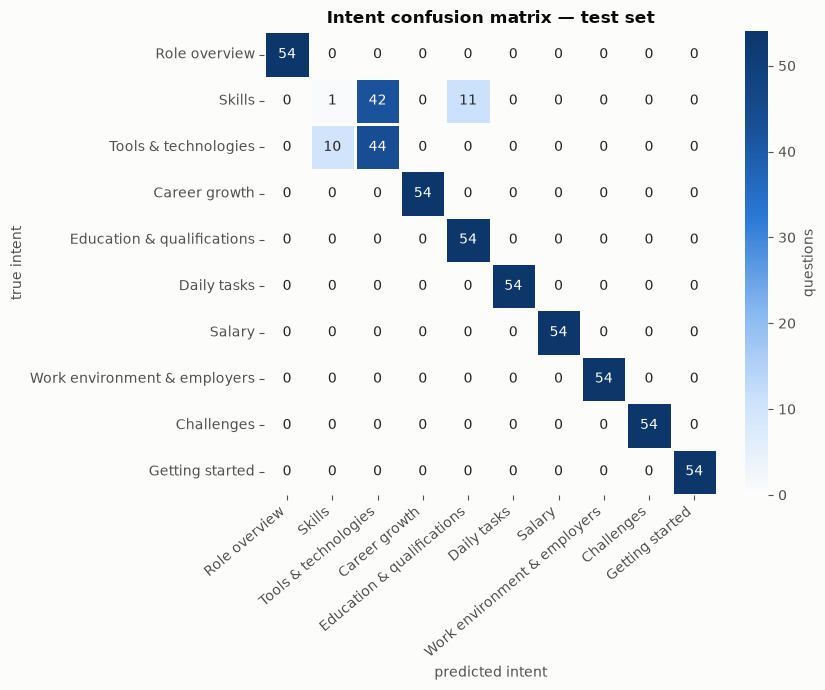

Role confusions on the test set: none


In [42]:
cm = confusion_matrix(y_int, pt.pred_intent, labels=INTENTS)
names = [INTENT_NAMES[i] for i in INTENTS]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ_BLUES, xticklabels=names, yticklabels=names, cbar_kws={"label": "questions"},
            linewidths=1, linecolor="#fcfcfb", ax=ax); ax.grid(False)
ax.set(title="Intent confusion matrix — test set", xlabel="predicted intent", ylabel="true intent")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

role_cm = pd.crosstab(pt.pred_role, y_role)
off = [(t, p, n) for t in role_cm.columns for p, n in role_cm[t].items() if p != t and n > 0]
print("Role confusions on the test set:", off if off else "none")

In [43]:
# End-to-end comparison: which approach finds an answer from the right (role, intent) group?
rows = {}
for name, sims in [("Retrieval only: TF-IDF cosine", tfidf_sims(train_df, test_df, BEST_PRE)),
                   ("Retrieval only: MiniLM cosine", emb_sims(train_df, test_df)),
                   (f"Retrieval only: {BEST_ENC_LABEL} cosine", emb_sims(train_df, test_df, BEST_ENC, BEST_PROMPT))]:
    rows[name] = retrieval_metrics(sims, train_df, test_df)
rows["Hybrid: role clf + intent clf + cosine (no thresholds)"] = {"Hit@1": pt.correct.mean(),
                                                                 "Hit@3": np.nan, "Hit@5": np.nan, "MRR": np.nan}
e2e = pd.DataFrame(rows).T
e2e.round(3)

,Hit@1,Hit@3,Hit@5,MRR
Retrieval only: TF-IDF cosine,0.293,0.552,0.633,0.462
Retrieval only: MiniLM cosine,0.700,0.952,0.985,0.816
Retrieval only: e5-small-v2 cosine,0.907,0.994,0.998,0.949
Hybrid: role clf + intent clf + cosine (no thresholds),0.883,NaN,NaN,NaN


In [44]:
ans = pt.decision == "answer"
system = {
    "coverage (answered)": ans.mean(),
    "accuracy of answered": pt.correct[ans].mean(),
    "wrong-answer rate (of all)": (ans & ~pt.correct).mean(),
    "asked to clarify topic": (pt.decision == "clarify_intent").mean(),
    "asked to clarify role": (pt.decision == "clarify_role").mean(),
    "fallback": (pt.decision == "fallback").mean(),
}
def decisions(queries):
    p = eval_bot.predict(queries)
    return pd.Series([eval_bot.decide(r, i, s) for r, i, s in zip(p.role_conf, p.intent_conf, p.max_similarity)])
ood_dec, rf_dec = decisions(OOD_TEST), decisions(ROLEFREE_TEST)
system["OOD test: fallback rate"] = (ood_dec == "fallback").mean()
system["role-free test: clarify-role rate"] = (rf_dec == "clarify_role").mean()
system_table = pd.Series(system, name="value").to_frame()
display(system_table.round(3))
print("OOD test decisions:", ood_dec.value_counts().to_dict(), "| role-free test decisions:", rf_dec.value_counts().to_dict())

,value
coverage (answered),0.894
accuracy of answered,0.952
wrong-answer rate (of all),0.043
asked to clarify topic,0.106
asked to clarify role,0.000
fallback,0.000
OOD test: fallback rate,1.000
role-free test: clarify-role rate,0.833


OOD test decisions: {'fallback': 15} | role-free test decisions: {'clarify_role': 5, 'fallback': 1}


**Top-2 and "Did you mean".** When the bot answers but the two best topics are nearly tied, it also offers the
second topic. How often is the right topic among the top two, and how often does the offer rescue a wrong answer?

In [45]:
top2 = pt.role_ok & ((pt.pred_intent.to_numpy() == y_int) | (pt.intent2.to_numpy() == y_int))
offered = (pt.decision == "answer") & ((pt.intent_conf - pt.intent2_conf) < THRESHOLDS.max_ambiguity_margin)
rescued = offered & ~pt.correct & pt.role_ok & (pt.intent2.to_numpy() == y_int)
pd.Series({"top-1 accuracy (role + intent)": pt.correct.mean(), "top-2 accuracy (role + intent)": top2.mean(),
           "answers with a 'Did you mean' offer": offered[pt.decision == "answer"].mean(),
           "wrong answers rescued by the offer": rescued.sum() / max((~pt.correct & (pt.decision == "answer")).sum(), 1),
           "answered correctly or right topic offered": (pt.correct | rescued).mean()}, name="test").round(3).to_frame()

,test
top-1 accuracy (role + intent),0.883
top-2 accuracy (role + intent),0.911
answers with a 'Did you mean' offer,0.122
wrong answers rescued by the offer,0.217
answered correctly or right topic offered,0.893


**Robustness check — 3-fold leave-one-paraphrase-out cross-validation.** The single test split uses one
particular wording per intent. Rotating which paraphrase slot is held out gives a less wording-dependent
estimate (the configuration chosen above is kept fixed; this is a supplementary estimate).

In [46]:
cv_rows = []
for k in range(3):
    tr, te = df[df.paraphrase_slot != k].reset_index(drop=True), df[df.paraphrase_slot == k].reset_index(drop=True)
    b = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(tr, extra=EXTRA)
    p = b.predict(te.question)
    joint = (p.pred_role.to_numpy() == te.role.to_numpy()) & (p.pred_intent.to_numpy() == te.intent.to_numpy())
    cv_rows.append({"held-out slot": k,
                    "role accuracy": accuracy_score(te.role, p.pred_role),
                    "intent accuracy": accuracy_score(te.intent, p.pred_intent),
                    "intent macro-F1": f1_score(te.intent, p.pred_intent, average="macro"),
                    "hybrid Hit@1": joint.mean(),
                    "TF-IDF retrieval Hit@1": retrieval_metrics(tfidf_sims(tr, te, BEST_PRE), tr, te)["Hit@1"],
                    f"{BEST_ENC_LABEL} retrieval Hit@1": retrieval_metrics(emb_sims(tr, te, BEST_ENC, BEST_PROMPT), tr, te)["Hit@1"]})
cv = pd.DataFrame(cv_rows).set_index("held-out slot")
display(cv.round(3))
cv.agg(["mean", "std"]).round(3)

,role accuracy,intent accuracy,intent macro-F1,hybrid Hit@1,TF-IDF retrieval Hit@1,e5-small-v2 retrieval Hit@1
held-out slot,,,,,,
0,1.0,0.963,0.962,0.963,0.481,0.878
1,1.0,0.800,0.766,0.800,0.374,0.796
2,1.0,0.883,0.857,0.883,0.293,0.907


,role accuracy,intent accuracy,intent macro-F1,hybrid Hit@1,TF-IDF retrieval Hit@1,e5-small-v2 retrieval Hit@1
mean,1.0,0.882,0.862,0.882,0.383,0.860
std,0.0,0.081,0.098,0.081,0.095,0.058


### 13.1 Retrain on the full dataset and save the model

For deployment, the knowledge base should contain **all** 1,620 answers, so the final model is refitted on
the full dataset with the configuration and thresholds selected above. The test-set metrics stored in the
metadata are the ones measured above (on the model trained without the test slot).

In [47]:
final_bot = CareerChatbot(**BEST_CONFIG, thresholds=THRESHOLDS).fit(df, extra=EXTRA, meta=META)
final_bot.save(cc.MODEL_PATH, metadata={
    "test_metrics": {"role_accuracy": float(cls_table.loc["Role classifier (54 classes)", "accuracy"]),
                     "intent_accuracy": float(cls_table.loc["Intent classifier (10 classes)", "accuracy"]),
                     "intent_macro_f1": float(cls_table.loc["Intent classifier (10 classes)", "macro_f1"]),
                     "hybrid_hit_at_1": float(pt.correct.mean()),
                     "coverage": float(system["coverage (answered)"]),
                     "accuracy_of_answered": float(system["accuracy of answered"])},
    "cv_mean": {k: float(v) for k, v in cv.mean().items()},
    "preprocessing": repr(BEST_PRE),
})
reloaded = CareerChatbot.load(cc.MODEL_PATH).warmup()   # warmup also checks the encoder fingerprint
check_q = test_df.question.head(20)
pd.testing.assert_frame_equal(reloaded.predict(check_q), final_bot.predict(check_q), check_exact=False)  # reload sanity check
print("Saved:", cc.MODEL_PATH.relative_to(Path.cwd()) if cc.MODEL_PATH.is_relative_to(Path.cwd()) else cc.MODEL_PATH,
      f"({cc.MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Saved: models\career_chatbot.joblib (5.1 MB)


### 13.2 Realistic questions: handling variations in user input

The frozen realistic set (§7) is scored through `respond()` — the exact code path of the app. We compare
three systems: the **v1.0** model (previous version, kept in `backup/v1.0/`), the **new model without** the
query normaliser, and the **new model with** it. A question counts as correct only if the bot gives the
expected behaviour (right career *and* topic for answers; no answer for unknown careers and off-topic questions).

In [48]:
V1_PATH = Path("backup/v1.0/models/career_chatbot.joblib")
v1_bot = CareerChatbot.load(V1_PATH)
real_v1 = ce.evaluate_queries(v1_bot, realistic)
real_nonorm = ce.evaluate_queries(reloaded, realistic, use_normalizer=False)
real_new = ce.evaluate_queries(reloaded, realistic)
by_cat = pd.DataFrame({"v1.0": real_v1.groupby("category").correct.mean(),
                       "v1.1 without normaliser": real_nonorm.groupby("category").correct.mean(),
                       "v1.1 (final)": real_new.groupby("category").correct.mean()})
by_cat = by_cat.reindex(["informal", "abbreviation", "typo", "overlap", "role_free", "unknown_role", "off_topic"])
by_cat.loc["ALL (64 questions)"] = [real_v1.correct.mean(), real_nonorm.correct.mean(), real_new.correct.mean()]
by_cat.round(3)

,v1.0,v1.1 without normaliser,v1.1 (final)
category,,,
informal,1.000,1.000,1.000
abbreviation,0.400,0.400,0.800
typo,0.400,0.300,0.900
overlap,1.000,1.000,1.000
role_free,1.000,0.667,0.667
unknown_role,1.000,1.000,1.000
off_topic,1.000,1.000,1.000
ALL (64 questions),0.806,0.758,0.919


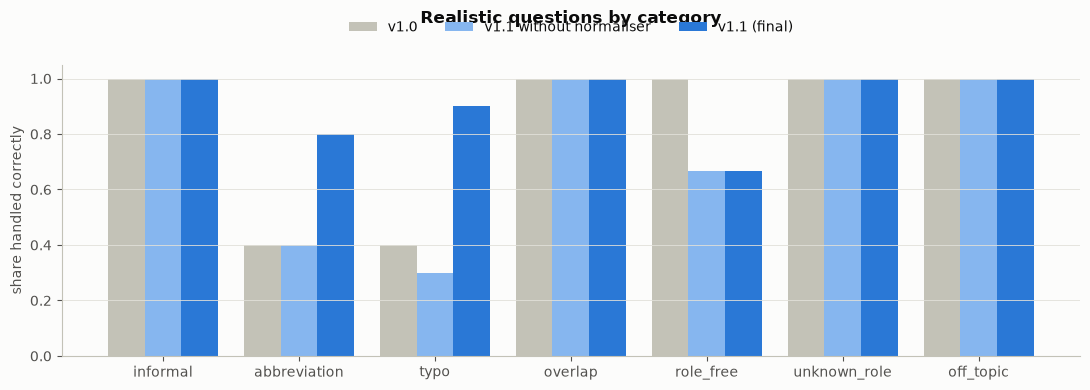

In [49]:
fig, ax = plt.subplots(figsize=(11, 4))
plot_cat = by_cat.drop("ALL (64 questions)")
x = np.arange(len(plot_cat)); w = 0.27
for i, (col, color) in enumerate(zip(plot_cat.columns, ["#c3c2b7", "#86b6ef", BLUE])):
    ax.bar(x + (i - 1) * w, plot_cat[col], width=w, color=color, label=col)
ax.set_xticks(x); ax.set_xticklabels(plot_cat.index); ax.grid(False, axis="x")
ax.set(ylim=(0, 1.05), ylabel="share handled correctly"); ax.set_title("Realistic questions by category", pad=30)
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

In [50]:
# Classification metrics on the realistic questions that expect an answer (career + topic labels exist)
exp_ans = real_new[real_new.expected == "answer"]
print(f"Questions expecting an answer: {len(exp_ans)}; answered: {(exp_ans.decision == 'answer').mean():.1%}")
pd.DataFrame({"Role": cls_metrics(exp_ans.exp_role, exp_ans.pred_role),
              "Intent": cls_metrics(exp_ans.exp_intent, exp_ans.pred_intent)}).T.round(3)

Questions expecting an answer: 38; answered: 92.1%


,accuracy,macro_precision,macro_recall,macro_f1
Role,1.0,1.0,1.0,1.0
Intent,1.0,1.0,1.0,1.0


### 13.3 Multi-turn dialogues: follow-up memory and usability

Usability is measured as **task success**: a scripted dialogue succeeds only if *every* turn gets the expected
behaviour. Follow-up questions such as *"how much do they earn?"* name no career, so without memory the bot can
only ask which career is meant. With memory (`ConversationContext`) the career (or the topic, when the user
only names a new career) is filled from the previous turn — unless the follow-up mentions a word the bot does
not know (e.g. *pilot*), it is off-topic, or the memory is older than a few turns.

In [51]:
dlg_off = ce.run_dialogues(reloaded, conversations, memory=False)
dlg_on = ce.run_dialogues(reloaded, conversations, memory=True)
dlg_v1 = ce.run_dialogues(v1_bot, conversations, memory=False)
dialog_table = pd.DataFrame({
    name: {"turn accuracy": d.correct.mean(),
           "follow-up turn accuracy": d[d.turn > 1].correct.mean(),
           "dialogue task success": d.groupby("dialog_id").correct.all().mean()}
    for name, d in [("v1.0 (no memory)", dlg_v1), ("v1.1 memory off", dlg_off), ("v1.1 memory on (final)", dlg_on)]}).T
display(dialog_table.round(3))
print("Turns where memory filled a gap:", dlg_on.used_memory.value_counts().to_dict())

,turn accuracy,follow-up turn accuracy,dialogue task success
v1.0 (no memory),0.500,0.222,0.083
v1.1 memory off,0.500,0.222,0.083
v1.1 memory on (final),0.833,0.778,0.583


Turns where memory filled a gap: {'role': 10}


### 13.4 Performance: speed and size

Measured on this machine: warm reply time of `respond()` (median and 95th percentile over the realistic
questions), the cold start of a fresh Python process (import + load + encoder warm-up, i.e. what the app pays
once at startup), and the size of the saved model file.

In [52]:
lat_v1 = ce.reply_latency(v1_bot, realistic["query"], repeats=2)
lat_new = ce.reply_latency(reloaded, realistic["query"], repeats=2)
cold_v1, cold_new = ce.cold_start(V1_PATH), ce.cold_start(cc.MODEL_PATH)
perf = pd.DataFrame({
    "v1.0": {**lat_v1, **{f"cold start {k}": v for k, v in cold_v1.items()}, "model file MB": V1_PATH.stat().st_size / 1e6},
    "v1.1 (final)": {**lat_new, **{f"cold start {k}": v for k, v in cold_new.items()},
                     "model file MB": cc.MODEL_PATH.stat().st_size / 1e6}})
perf.round(2)

,v1.0,v1.1 (final)
median_ms,10.13,23.23
p95_ms,12.13,39.29
cold start import_s,2.44,2.30
cold start load_s,0.01,0.02
cold start warmup_s,9.04,7.28
cold start total_s,11.49,9.60
model file MB,4.00,5.14


### 13.5 Before vs after (v1.0 → v1.1)

All numbers below are produced in this notebook run, except the v1.0 held-out test scores, which are read from
the v1.0 model's saved metadata (they were produced by the v1.0 version of this notebook on the same split).

In [53]:
v1_meta = json.loads(Path("backup/v1.0/models/model_metadata.json").read_text())
comparison = pd.DataFrame({
    "v1.0": {"intent accuracy (held-out test)": v1_meta["test_metrics"]["intent_accuracy"],
             "intent macro-F1 (held-out test)": v1_meta["test_metrics"]["intent_macro_f1"],
             "hybrid Hit@1 (3-fold CV mean)": v1_meta["cv_mean"]["hybrid Hit@1"],
             "realistic questions handled correctly": real_v1.correct.mean(),
             "dialogue task success": dlg_v1.groupby("dialog_id").correct.all().mean(),
             "warm reply median (ms)": lat_v1["median_ms"], "cold start (s)": cold_v1["total_s"]},
    "v1.1": {"intent accuracy (held-out test)": cls_table.loc["Intent classifier (10 classes)", "accuracy"],
             "intent macro-F1 (held-out test)": cls_table.loc["Intent classifier (10 classes)", "macro_f1"],
             "hybrid Hit@1 (3-fold CV mean)": cv["hybrid Hit@1"].mean(),
             "realistic questions handled correctly": real_new.correct.mean(),
             "dialogue task success": dlg_on.groupby("dialog_id").correct.all().mean(),
             "warm reply median (ms)": lat_new["median_ms"], "cold start (s)": cold_new["total_s"]}})
display(comparison.round(3))

# Re-save the final model with the complete evaluation summary in its metadata (read by the app and README)
final_bot.save(cc.MODEL_PATH, metadata={
    "test_metrics": {"role_accuracy": float(cls_table.loc["Role classifier (54 classes)", "accuracy"]),
                     "intent_accuracy": float(cls_table.loc["Intent classifier (10 classes)", "accuracy"]),
                     "intent_macro_f1": float(cls_table.loc["Intent classifier (10 classes)", "macro_f1"]),
                     "hybrid_hit_at_1": float(pt.correct.mean()), "top2_accuracy": float(top2.mean()),
                     "coverage": float(system["coverage (answered)"]),
                     "accuracy_of_answered": float(system["accuracy of answered"])},
    "cv_mean": {k: float(v) for k, v in cv.mean().items()},
    "realistic_accuracy": {k: float(v) for k, v in by_cat["v1.1 (final)"].items()},
    "dialogue": {k: float(v) for k, v in dialog_table.loc["v1.1 memory on (final)"].items()},
    "performance": {k: float(v) for k, v in perf["v1.1 (final)"].items()},
    "v1_comparison": {k: {kk: float(vv) for kk, vv in col.items()} for k, col in comparison.items()},
    "encoder_label": BEST_ENC_LABEL, "preprocessing": repr(BEST_PRE), "eval_set_sha256": eval_hashes,
    "extra_wordings_used": USE_EXTRA, "extra_wordings_val_macro_f1_change": float(gain),
})
print(cc.METADATA_PATH.read_text())

,v1.0,v1.1
intent accuracy (held-out test),0.715,0.883
intent macro-F1 (held-out test),0.646,0.857
hybrid Hit@1 (3-fold CV mean),0.829,0.882
realistic questions handled correctly,0.806,0.919
dialogue task success,0.083,0.583
warm reply median (ms),10.130,23.228
cold start (s),11.490,9.600


{
  "sklearn_version": "1.9.1",
  "dataset": "Pradeep016/career-guidance-qa-dataset",
  "embedding_model": "intfloat/e5-small-v2",
  "encoder_prompt": "query: ",
  "intent_features": "embedding",
  "augment_with_answers": false,
  "kb_size": 1620,
  "n_roles": 54,
  "role_C": 10.0,
  "intent_C": 100.0,
  "ngram_range": [
    1,
    2
  ],
  "use_normalizer": true,
  "gate_on_raw": false,
  "extra_training_questions": 2700,
  "thresholds": {
    "min_similarity": 0.864,
    "min_role_conf": 0.312,
    "min_intent_conf": 0.603,
    "max_ambiguity_margin": 0.6,
    "min_meta_similarity": 0.883,
    "min_meta_margin": 0.02
  },
  "test_metrics": {
    "role_accuracy": 1.0,
    "intent_accuracy": 0.8833333333333333,
    "intent_macro_f1": 0.8566903684550743,
    "hybrid_hit_at_1": 0.8833333333333333,
    "top2_accuracy": 0.9111111111111111,
    "coverage": 0.8944444444444445,
    "accuracy_of_answered": 0.9523809523809523
  },
  "cv_mean": {
    "role accuracy": 1.0,
    "intent accuracy": 

## 14. Sample chatbot conversations

These use the **reloaded saved model** through `respond()` — exactly what the Streamlit app calls, including the
conversation memory. The messages are written for this demo (not from the dataset or the frozen test sets).

In [54]:
def conversation(messages, bot=reloaded):
    ctx = ConversationContext()
    for q in messages:
        r = bot.respond(q, ctx); ctx = r.context
        tag = f"[{r.kind}"
        if r.kind != "invalid":
            tag += f" | {r.role} ({r.role_conf:.2f}) | {r.intent} ({r.intent_conf:.2f}) | sim {r.similarity:.2f}"
        if r.used_memory:
            tag += f" | {r.used_memory} from memory"
        print(f"You: {q!r}\nBot {tag}]")
        if r.corrections:
            print(f"     (read as: {r.normalized_query!r})")
        print(f"     {r.text}")
        if r.alternative:
            print(f"     Did you mean: {r.alternative[1]!r}?")
        print()
    print("-" * 100)

conversation(["Hi! What does a Data Scientist do?", "how much do they make?", "and which tools do they use?",
              "what about a Data Analyst?"])
conversation(["wat skils does a sofware enginer need", "ml engineer salary", "what is an SRE?"])
conversation(["What is the average salary?", "for a Web Developer", "What's the weather like today?", "   "])
conversation(["What is a Data Analyst, Data Scientist, Business Analyst?", "how much do they earn?"])
conversation(["hello", "what is the best job for me?", "I like coding and maths", "how much do they earn?",
              "list all the jobs for computer science", "thanks"])

You: 'Hi! What does a Data Scientist do?'
Bot [answer | Data Scientist (0.99) | role_overview (1.00) | sim 0.98]
     A Data Scientist extracts meaningful insights from data by using advanced analytical techniques, statistical modeling, and machine learning to solve complex business problems.

You: 'how much do they make?'
Bot [answer | Data Scientist (0.99) | salary (1.00) | sim 0.96 | role from memory]
     Entry-level Data Scientists earn between $70,000 to $100,000 annually, while experienced professionals can earn over $150,000.

You: 'and which tools do they use?'
Bot [answer | Data Scientist (1.00) | tools_technologies (0.97) | sim 0.96 | role from memory]
     Data Scientists use tools like Python, R, Jupyter Notebooks, TensorFlow, PyTorch, SQL, Tableau, and cloud platforms like AWS or Azure.

You: 'what about a Data Analyst?'
Bot [answer | Data Analyst (1.00) | role_overview (0.88) | sim 0.97]
     A Data Analyst collects, processes, and performs statistical analyses on large 

You: 'What is the average salary?'
Bot [clarify_role | Corporate Social Responsibility (CSR) Manager (Entry-level) (0.03) | salary (1.00) | sim 0.91]
     It sounds like you're asking about **salary**, but I'm not sure which career you mean. Could you name the role? (Best guesses: Corporate Social Responsibility (CSR) Manager (Entry-level), Software Engineer, Knowledge Manager (Junior level).)



You: 'for a Web Developer'
Bot [answer | Web Developer (1.00) | role_overview (0.64) | sim 0.95]
     A Web Developer is responsible for designing, coding, and maintaining websites. They work on both the front-end (user interface) and back-end (server-side logic) of websites, ensuring they function efficiently and are user-friendly.
     Did you mean: 'What qualifications do I need to become a Web Developer?'?

You: "What's the weather like today?"
Bot [clarify_role | Software Engineer (0.03) | daily_tasks (0.97) | sim 0.87]
     It sounds like you're asking about **daily tasks**, but I'm not sure which career you mean. Could you name the role? (Best guesses: Software Engineer, Corporate Social Responsibility (CSR) Manager (Entry-level), Business Analyst.)

You: '   '
Bot [invalid]
     Please type a question.

----------------------------------------------------------------------------------------------------
You: 'What is a Data Analyst, Data Scientist, Business Analyst?'
Bot [answer

You: 'what is the best job for me?'
Bot [meta | None (0.00) | None (0.00) | sim 0.99]
     Happy to help you choose! Tell me what you enjoy or are good at, e.g. *"I like coding and maths"* or *"I enjoy design and talking to people"*, and I'll suggest careers that fit.



You: 'I like coding and maths'
Bot [meta | None (0.00) | None (0.00) | sim 0.94]
     Based on what you told me, these careers could fit:

1. **Web Developer** — A Web Developer is responsible for designing, coding, and maintaining websites.
2. **Software Engineer** — A Software Engineer designs, develops, tests, and maintains software applications, ensuring that they meet functional and non-functional requirements.
3. **Game Developer** — A Game Developer designs, develops, and programs interactive video games for various platforms such as consoles, PCs, and mobile devices.

Ask me about any of them, e.g. their skills or salary.

You: 'how much do they earn?'
Bot [answer | Web Developer (0.96) | salary (1.00) | sim 0.97 | role from memory]
     **Web Developer:** Web Developers earn between $50,000 and $85,000 annually on average. Experienced professionals and those with specialized skills can earn up to $100,000 or more.

**Software Engineer:** Software Engineers typically earn betwe

You: 'thanks'
Bot [meta | None (0.00) | None (0.00) | sim 1.00]
     You're welcome! Ask me anything else about careers.

----------------------------------------------------------------------------------------------------


## 15. Error analysis, limitations and possible improvements

### 15.1 Which intents are confused on the test set?

errors
true                 predicted                         
Skills               Tools & technologies            42
                     Education & qualifications      11
Tools & technologies Skills                          10

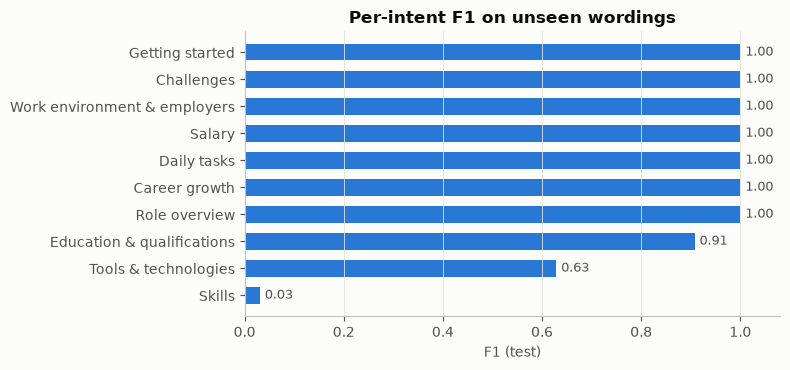

In [55]:
err = test_df.assign(pred_intent=pt.pred_intent, intent_conf=pt.intent_conf)[~pt.intent_ok.to_numpy()]
pairs = (err.assign(true=err.intent.map(INTENT_NAMES), predicted=err.pred_intent.map(INTENT_NAMES))
            .groupby(["true", "predicted"]).size().sort_values(ascending=False).rename("errors").head(8))
display(pairs.to_frame())

per_intent = pd.Series(f1_score(y_int, pt.pred_intent, labels=INTENTS, average=None), index=names).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(per_intent.index, per_intent.values, color=BLUE, height=0.6); ax.grid(False, axis="y")
for y, v in enumerate(per_intent.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK2, fontsize=9)
ax.set(xlim=(0, 1.08), xlabel="F1 (test)", title="Per-intent F1 on unseen wordings")
plt.tight_layout(); plt.show()

In [56]:
# Why? Compare the training wordings with the unseen test wording for the weakest intents.
for intent_name in per_intent.index[:3]:
    intent = next(k for k, v in INTENT_NAMES.items() if v == intent_name)
    tpl = chk.assign(intent=[INTENTS[p // 3] for p in chk.position])
    tpl = tpl[tpl.intent == intent].groupby(chk.position % 3).template.agg(lambda s: s.value_counts().index[0])
    wrong = err[err.intent == intent].pred_intent.map(INTENT_NAMES).value_counts().head(2).to_dict()
    print(f"{intent_name}: train wordings = {tpl[0]!r}, {tpl[1]!r}\n   test wording = {tpl[2]!r}\n   most common wrong predictions: {wrong}\n")

Skills: train wordings = 'What skills are required to become a <ROLE>?', 'What are the essential skills for a successful <ROLE>?'
   test wording = 'Which programming languages are important for a <ROLE>?'
   most common wrong predictions: {'Tools & technologies': 42, 'Education & qualifications': 11}

Tools & technologies: train wordings = 'What tools does a <ROLE> typically use?', 'What technologies are commonly used in the <ROLE> role?'
   test wording = 'Which software should a <ROLE> be proficient in?'
   most common wrong predictions: {'Skills': 10}

Education & qualifications: train wordings = 'What qualifications do I need to become a <ROLE>?', 'Do I need a degree to pursue a career as a <ROLE>?'
   test wording = 'What are the educational requirements for a <ROLE>?'
   most common wrong predictions: {}



In [57]:
err[["role", "question", "intent", "pred_intent", "intent_conf"]].sample(min(10, len(err)), random_state=SEED)

,role,question,intent,pred_intent,intent_conf
521,Account Manager (Junior level),Which programming languages are important for an Account Manager?,skills,tools_technologies,0.594796
481,Operations Executive (Entry-level),Which programming languages are important for an Operations Executive?,skills,tools_technologies,0.456306
1,Data Scientist,Which programming languages are important for a Data Scientist?,skills,education,0.524998
341,Market Development Manager (Junior level),Which programming languages are important for a Market Development Manager (Junior level)?,skills,tools_technologies,0.345153
32,Machine Learning Engineer,Which software should a Machine Learning Engineer be proficient in?,tools_technologies,skills,0.522596
281,Content Strategist,Which programming languages are important for a Content Strategist?,skills,tools_technologies,0.517965
121,Game Developer,Which programming languages are important for a Game Developer?,skills,tools_technologies,0.352383
82,UX/UI Designer,Which software should a UX/UI Designer be proficient in?,tools_technologies,skills,0.517520
191,E-commerce Specialist,Which programming languages are important for an E-commerce Specialist?,skills,tools_technologies,0.438315
511,Franchise Manager (Entry-level),Which programming languages are important for a Franchise Manager?,skills,tools_technologies,0.591686


### 15.2 Errors on the realistic questions and dialogues

Every realistic question and dialogue turn the final model gets wrong (§13.2–13.3):

In [58]:
cols = ["category", "query", "expected", "decision", "exp_role", "pred_role", "exp_intent", "pred_intent", "normalized"]
display(real_new.loc[~real_new.correct, cols])
dlg_err = dlg_on.loc[~dlg_on.correct, ["dialog_id", "turn", "query", "expected", "decision", "exp_role", "pred_role",
                                       "exp_intent", "pred_intent", "used_memory"]]
dlg_err

,category,query,expected,decision,exp_role,pred_role,exp_intent,pred_intent,normalized
13,abbreviation,what is an sre,answer,clarify_role,Site Reliability Engineer (SRE),Site Reliability Engineer (SRE),role_overview,role_overview,what is an sre
20,abbreviation,what software does a mobile dev use,answer,clarify_role,Mobile App Developer,Mobile App Developer,tools_technologies,tools_technologies,what software does a mobile developer use
30,typo,wrok environment for a cloud database enginer,answer,clarify_intent,Cloud Database Engineer,Cloud Database Engineer,work_environment,work_environment,wrok environment for a cloud database engineer
38,role_free,how much can i earn,clarify_role,meta,,NaN,salary,NaN,how much can i earn
39,role_free,what skills should i learn,clarify_role,meta,,NaN,skills,NaN,what skills should i learn


,dialog_id,turn,query,expected,decision,exp_role,pred_role,exp_intent,pred_intent,used_memory
3,D02,1,Tell me about being a Web Developer,answer,clarify_intent,Web Developer,Web Developer,role_overview,role_overview,NaN
9,D04,2,what about a Mobile App Developer?,answer,answer,Mobile App Developer,Mobile App Developer,salary,role_overview,NaN
18,D08,2,as a Cloud Database Engineer,answer,answer,Cloud Database Engineer,Cloud Database Engineer,salary,role_overview,NaN
22,D09,4,and their salary?,answer,fallback,Media Buyer,Corporate Social Responsibility (CSR) Manager (Entry-level),salary,salary,NaN
29,D12,2,what problems do they face?,answer,fallback,Product Owner (Entry-level),Corporate Social Responsibility (CSR) Manager (Entry-level),challenges,challenges,NaN


### 15.3 Discussion

**Effect of the extra training wordings (§7.1, §11.5).** Adding 50 hand-written wordings (2,700 training
questions) raised the validation macro-F1 of the topic classifier from about 0.77 to 0.88 and made its
probabilities much sharper (log-loss about 1.06 → 0.35), so they were kept. On the held-out test wording, topic
accuracy rose to about 0.88, and the *Work environment* confusion seen without them disappeared. Because the
model is now more confident, the data-driven intent threshold is higher: the bot asks *"which topic?"* for about
one test question in ten instead of guessing, and the answers it does give are right about 95% of the time.

**What still goes wrong (tables above)**
1. **Skills vs tools.** Most remaining held-out errors are *Skills* questions worded *"Which programming languages
   are important for …?"*, predicted as **Tools & technologies** (or Education). Section 4 showed that the stored
   answers of that question read like tools answers, so part of this is **label ambiguity in the dataset**; the
   extra wordings deliberately avoided the test-only words *programming languages* (§7.1), so this error was not
   "trained away".
2. **Confident mistakes are rarer but still confident.** With sharper probabilities the second-best topic is less
   often the right one (top-2 accuracy ≈ 0.91), so the *"Did you mean"* offer rescues fewer errors than before.
3. **Short follow-ups after a long answer** (*"and their salary?"*, *"what problems do they face?"*) can fall
   below the in-scope similarity threshold and get a fallback instead of using the remembered career. The e5
   encoder places all sentences in a narrow similarity band (0.8–1.0), which makes this threshold delicate; for the
   same reason some off-topic sentences (e.g. the weather question in §14) pass the in-scope check and the bot asks
   which career is meant instead of falling back — no wrong answer, but a fallback would be better.
4. **Switching career while keeping the topic** (*"What is the salary of a Game Developer?"* → *"what about a
   Mobile App Developer?"*) is answered with the role overview: memory fills a missing *career*, but a newly named
   career with a vague question is classified on its own. Vague openers such as *"Tell me about being a Web
   Developer"* now get a "which topic?" clarification.
5. **Very short abbreviations** (*"what is an sre"*, *"mobile dev"*) give too little text for a confident career
   prediction, so the bot asks which career is meant (a safe outcome). Memory is deliberately *not* used when the
   message names another career (a regression test covers this).
6. **Small talk and career discovery (§12.1) have a cost.** Two role-free career questions in the realistic set
   (*"how much can I earn"*, *"what skills should I learn"*) are now answered with *"tell me what you enjoy"*
   instead of *"which career do you mean?"*: their similarity to the discovery examples beats the career questions
   by just over the calibrated margin. The reply is still sensible, but it is counted as an error; the margin was
   calibrated on the role-free *calibration* questions and was not re-tuned on this test set.
7. **TF-IDF retrieval matches words, not meaning** (Hit@1 ≈ 0.29 on the test set vs ≈ 0.91 for e5 embeddings):
   the reason the topic classifier uses sentence embeddings.

**Honesty note on the hand-written test sets.** The realistic questions and dialogues were written before any
tuning. After the first full run we inspected their errors and made two general fixes — (a) the normaliser no
longer rewrites abbreviations that the dataset's own questions already use (*CSR*), and (b) the in-scope threshold
is calibrated with typo'd *validation* questions and the raw-vs-normalised check is chosen on validation data.
The extra training wordings were checked automatically against these sets (§7.1). All decisions were made on
validation data or general rules, but because the realistic set had been seen, its scores are an optimistic
estimate rather than a fully blind benchmark.

### 15.4 Limitations
- **Small, templated dataset:** 54 careers × 10 topics with 3 wordings each and one fixed answer per question;
  only careers in the dataset are covered; salary figures are not localised or dated. Our extra wordings add
  variety to the *questions* only, not new careers or answers.
- **Derived intent labels:** verified (templates and answer similarity), but a few positions are genuinely
  ambiguous between two topics.
- **Hand-written data is small and single-author:** 50 extra training wordings, 64 realistic questions,
  12 dialogues, 15 + 15 off-topic and 6 + 6 role-free questions.
- **Narrow similarity range of the chosen encoder** makes the in-scope threshold sensitive (see 15.3, point 3).
- **Session memory only:** one remembered career/topic per conversation, expiring after a few turns; nothing is
  stored between sessions.
- The encoder (`e5-small-v2`, ~130 MB) is downloaded from the Hugging Face Hub on the first run.

### 15.5 Possible improvements
- **More, and more varied, wordings** — ideally collected from real users rather than written by one author.
- **Merge or multi-label the overlapping topics** (skills ↔ tools).
- **A separate out-of-scope detector** (e.g. a small classifier on embeddings trained on in-scope vs off-topic
  examples) instead of a single similarity threshold.
- **Topic carry-over when the career changes** ("what about a Mobile App Developer?" → previous topic).
- **Fine-tune the encoder** on the paraphrase groups, or re-rank candidates with a cross-encoder.

## 16. NLP pipeline diagram

The same pipeline runs in the notebook (training/evaluation) and in `app.py` (inference).

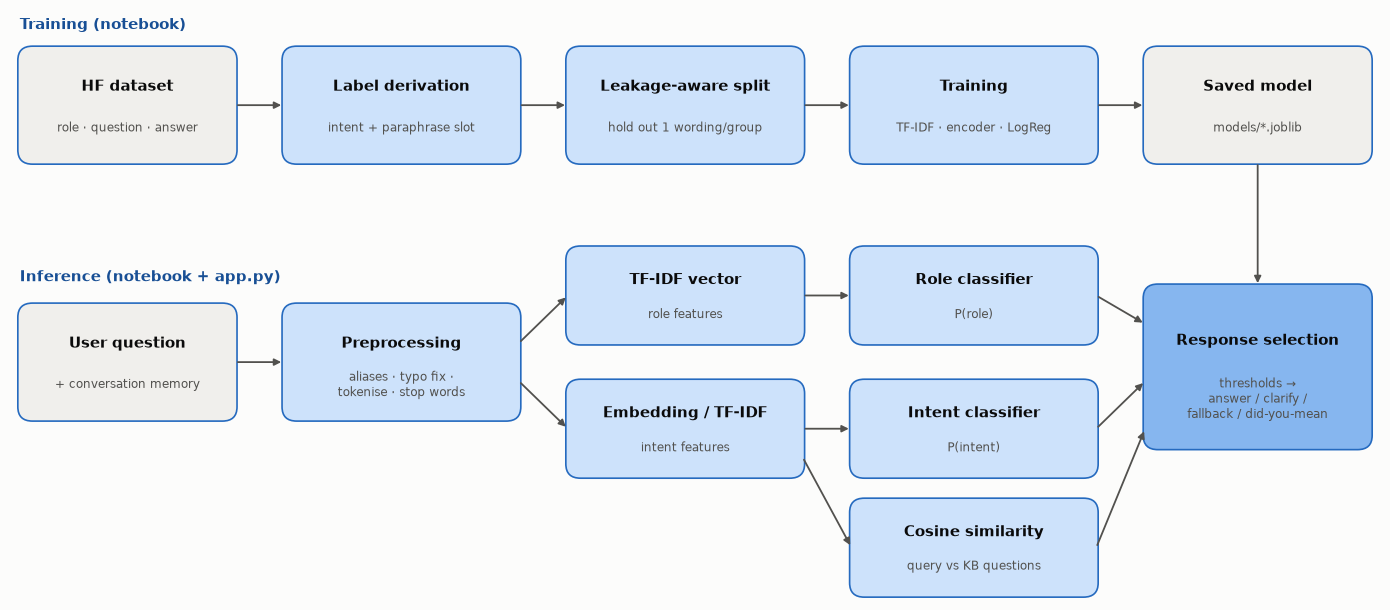

In [59]:
fig, ax = plt.subplots(figsize=(14, 6.2)); ax.set_xlim(0, 14); ax.set_ylim(0, 6.2); ax.axis("off")
def box(x, y, w, h, title, sub="", fc="#cde2fb"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=fc, ec="#256abf", lw=1.2))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10.5, weight="bold", color=INK)
    if sub: ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=8.5, color=INK2)
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.3))

box(0.1, 4.6, 2.2, 1.2, "HF dataset", "role · question · answer", "#f0efec")
box(2.8, 4.6, 2.4, 1.2, "Label derivation", "intent + paraphrase slot")
box(5.7, 4.6, 2.4, 1.2, "Leakage-aware split", "hold out 1 wording/group")
box(8.6, 4.6, 2.5, 1.2, "Training", "TF-IDF · encoder · LogReg")
box(11.6, 4.6, 2.3, 1.2, "Saved model", "models/*.joblib", "#f0efec")
for x in (2.3, 5.2, 8.1, 11.1): arrow(x, 5.2, x + 0.5, 5.2)

box(0.1, 1.9, 2.2, 1.2, "User question", "+ conversation memory", "#f0efec")
box(2.8, 1.9, 2.4, 1.2, "Preprocessing", "aliases · typo fix ·\ntokenise · stop words")
box(5.7, 2.7, 2.4, 1.0, "TF-IDF vector", "role features")
box(5.7, 1.3, 2.4, 1.0, "Embedding / TF-IDF", "intent features")
box(8.6, 2.7, 2.5, 1.0, "Role classifier", "P(role)")
box(8.6, 1.3, 2.5, 1.0, "Intent classifier", "P(intent)")
box(8.6, 0.05, 2.5, 1.0, "Cosine similarity", "query vs KB questions")
box(11.6, 1.6, 2.3, 1.7, "Response selection", "thresholds →\nanswer / clarify /\nfallback / did-you-mean", "#86b6ef")
arrow(2.3, 2.5, 2.8, 2.5); arrow(5.2, 2.7, 5.7, 3.2); arrow(5.2, 2.3, 5.7, 1.8)
arrow(8.1, 3.2, 8.6, 3.2); arrow(8.1, 1.8, 8.6, 1.8); arrow(8.1, 1.5, 8.6, 0.55)
arrow(11.1, 3.2, 11.6, 2.9); arrow(11.1, 1.8, 11.6, 2.3); arrow(11.1, 0.55, 11.6, 1.8)
arrow(12.75, 4.6, 12.75, 3.3)
ax.text(0.1, 6.0, "Training (notebook)", fontsize=11, weight="bold", color="#184f95")
ax.text(0.1, 3.35, "Inference (notebook + app.py)", fontsize=11, weight="bold", color="#184f95")
plt.tight_layout(); plt.show()

### 16.1 Walkthrough: from user input to response

Example: the user has just asked about Data Scientists and now types **"how much do they mak?"**

| Step | Component (`chatbot_core.py`) | What happens |
|---|---|---|
| 1. User input | `app.py` → `CareerChatbot.respond(query, context)` | Empty or overlong input is rejected with a message; the conversation context (last career, last topic) is passed in. |
| 2. Query normalisation | `QueryNormalizer.normalize` | Abbreviations are expanded and typos corrected towards knowledge-base words (*mak → make*). |
| 3. Preprocessing | `TextPreprocessor` (inside the TF-IDF vectorizer) | Unicode normalisation, lower-casing, tokenisation, stop-word removal (question words kept), stemming/lemmatisation as selected in §11. |
| 4. Feature extraction | `TfidfVectorizer` (word 1–2-grams) + sentence encoder | A sparse TF-IDF vector for the career, a dense sentence embedding for the topic. |
| 5. NLP models | two Logistic Regression classifiers | P(career) over 54 careers and P(topic) over 10 topics. Here the topic is clearly *salary* but no career is named, so P(career) is low. |
| 6. Cosine similarity | embeddings vs stored questions | The raw query's best similarity decides whether the question is in scope; within the predicted (career, topic) group the closest stored question is chosen. |
| 7. Response selection | `decide` + memory | Low career confidence would mean *"which career?"*; because the previous turn named Data Scientist, the memory fills the career and the stored salary answer for Data Scientists is returned. Nearly tied topics add a *"Did you mean"* offer. |
| 8. Response | `ChatResponse` → `app.py` | Answer text, confidence, matched question, corrections and suggested follow-up questions are shown. |

### 16.2 Code structure and programming concepts

| File | Role |
|---|---|
| `chatbot_core.py` | All NLP logic shared by the notebook and the app: normaliser, preprocessor, vectorizer, encoder, classifiers, response policy, memory, persistence |
| `chatbot_eval.py` | Evaluation helpers: frozen test sets (with hashes), realistic-question and dialogue scoring, latency and cold-start measurement |
| `career_guidance_chatbot.ipynb` | This notebook (generated by `build_notebook.py`): analysis, training, evaluation |
| `app.py` | Streamlit chat interface |
| `test_chatbot_core.py` | Assert-based tests of preprocessing, normaliser, decision policy, memory and the saved model |

Programming-language concepts used (instruction objective 4):
- **Object-oriented design** — classes with a single responsibility (`TextPreprocessor`, `QueryNormalizer`,
  `CareerChatbot`), a custom exception (`EncoderMismatchError`), a `classmethod` constructor (`QueryNormalizer.from_kb`).
- **Dataclasses** for plain data (`Thresholds`, `ChatResponse`, `NormalizedQuery`) and an **immutable** frozen
  dataclass for conversation state (`ConversationContext`), so the shared bot never stores per-user state.
- **Modules and imports** — one shared module guarantees the notebook and app run identical code.
- **Type hints and docstrings** on public functions; **higher-order functions** and closures (`intent_features`,
  `inner_cv`); **regular expressions** (tokeniser, alias matching); **caching** (`functools.lru_cache` for the encoder).
- **Persistence** — `joblib` serialisation plus JSON metadata; backward compatibility through class-level defaults.
- **Error handling and input validation** at the app boundary; **automated tests** (`python test_chatbot_core.py`).
- **Vectorised numerical code** with NumPy / pandas instead of Python loops for evaluation.

## 17. Conclusion

In [60]:
summary = pd.Series({
    "Role accuracy (test)": cls_table.loc["Role classifier (54 classes)", "accuracy"],
    "Intent accuracy (test)": cls_table.loc["Intent classifier (10 classes)", "accuracy"],
    "Intent macro-F1 (test)": cls_table.loc["Intent classifier (10 classes)", "macro_f1"],
    "TF-IDF retrieval Hit@1 (test)": e2e.loc["Retrieval only: TF-IDF cosine", "Hit@1"],
    f"{BEST_ENC_LABEL} retrieval Hit@1 (test)": e2e.loc[f"Retrieval only: {BEST_ENC_LABEL} cosine", "Hit@1"],
    "Hybrid Hit@1 (test)": pt.correct.mean(),
    "Hybrid top-2 accuracy (test)": top2.mean(),
    "Hybrid Hit@1 (3-fold CV mean)": cv["hybrid Hit@1"].mean(),
    "Coverage with thresholds (test)": system["coverage (answered)"],
    "Accuracy of answered (test)": system["accuracy of answered"],
    "OOD fallback rate (hand-written test)": system["OOD test: fallback rate"],
    "Realistic questions handled correctly (v1.1)": real_new.correct.mean(),
    "Dialogue task success (v1.1, memory on)": dlg_on.groupby("dialog_id").correct.all().mean(),
    "Warm reply median (ms)": lat_new["median_ms"],
}, name="value")
summary.round(3).to_frame()

,value
Role accuracy (test),1.000
Intent accuracy (test),0.883
Intent macro-F1 (test),0.857
TF-IDF retrieval Hit@1 (test),0.293
e5-small-v2 retrieval Hit@1 (test),0.907
Hybrid Hit@1 (test),0.883
Hybrid top-2 accuracy (test),0.911
Hybrid Hit@1 (3-fold CV mean),0.882
Coverage with thresholds (test),0.894
Accuracy of answered (test),0.952


**Summary.** The chatbot answers career questions from a Hugging Face QA dataset with a complete NLP pipeline:
query normalisation (abbreviations, typo correction), text preprocessing (normalisation, tokenisation, stop
words, stemming / lemmatisation), TF-IDF and sentence-embedding representations, Logistic Regression classifiers
for career and topic (trained on the dataset plus 2,700 extra hand-written question wordings that passed a
leakage check and a validation test), cosine-similarity answer selection, and a response policy with
clarification, fallback, *"Did you mean"*, several careers per question, small talk and interest-based career
suggestions (semantic search over the careers' answers), and conversation memory. The same saved model runs in the
Streamlit app.

**Key findings (table above and §13.5)**
- **Representation matters per sub-task:** TF-IDF n-grams are enough for the career (its name is in the
  question), while the topic needs meaning across different wordings — sentence embeddings are far ahead of every
  TF-IDF variant, and the best encoder (`e5-small-v2`, chosen on validation folds only) plus the extra training
  wordings raised held-out topic accuracy from 0.715 (v1.0) to about 0.88.
- **Handling real users** (query normaliser + calibrated in-scope check) raised the share of realistic questions
  handled correctly from about 81% to about 92%, mainly on typos and abbreviations, while no hand-written
  off-topic test question gets a career answer.
- **Conversation memory** turns follow-ups such as *"how much do they earn?"* from a clarification request into
  an answer: dialogue task success rose from about 8% to about 58%.
- **Remaining errors** come mostly from the skills ↔ tools overlap (partly label ambiguity in the dataset) and
  from a delicate in-scope threshold; when unsure, the bot now asks rather than guesses (about 95% of its answers
  on the test set are correct).

**Takeaway.** Match the representation to the signal (lexical for names, semantic for meaning), add training
variety carefully (checked for leakage, kept only if validation improves), evaluate on the kind of input real
users produce, and report failures as clearly as successes.